# 48 -- an ensemble for the live board, from predictions that already exist

**Stage 1 only. No model is trained anywhere in this notebook.** Every prediction it combines was
already on disk before it ran: 25-fold out-of-fold tables from notebooks 11 and 37, and full-data
blind columns from notebooks 12, 30, 40 and 47.

The question is narrow. This project has twelve scored submissions and one unconfirmed send, and
its board ranks are **126 / 138 / 86 / 94** on CYP1A2 / CYP2C9 / CYP2D6 / CYP3A4 -- four very
different competitive positions, so the work is per isoform throughout and no global weight vector
is fitted.

What it does, in order: inventory every saved blind prediction in the repository and establish how
many genuinely distinct prediction objects they amount to; measure residual correlation and
Krogh-Vedelsby ambiguity across the candidates; fit non-negative weights summing to one on
out-of-fold predictions under two objectives, honestly nested; test each resulting ensemble against
its own best single component on a resolution bar frozen before this notebook existed; run the
spread-ratio collapse check the compression record demands; and assemble validated submission
candidates.

**Nothing is sent.** The submission cell uses notebook 40's post-incident convention -- an explicit
`SEND = False` flag with the call under `if SEND:` and the printed message computed from the flag,
so the cell cannot describe itself wrongly.

`notebooks/32_deadzone_aid_retrain.ipynb` and `notebooks/40_single_object_ensemble.ipynb` are
never opened or executed; both carry live submission code. Their saved outputs are read only.

In [1]:
# Part 0 -- setup, provenance, and the environment assertions this project requires.
import hashlib, json, os, subprocess, sys, warnings
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

# Notebook 34 established that OMP_NUM_THREADS changes chemprop's training trajectory and breaks
# bit-reproducibility against notebook 05's stored scores, so it is asserted unset. Nothing here
# trains anything, but the environment is kept identical to the one every stored score was
# measured under. KMP_DUPLICATE_LIB_OK cannot be asserted after imports and is reported instead.
assert os.environ.get("OMP_NUM_THREADS") is None, (
    f"OMP_NUM_THREADS is set to {os.environ.get('OMP_NUM_THREADS')!r}; unset it and restart")
print("OMP_NUM_THREADS      : unset (asserted)")
print(f"KMP_DUPLICATE_LIB_OK : {os.environ.get('KMP_DUPLICATE_LIB_OK')!r} (reported, not asserted)")

OUT = REPO / "outputs" / "48_board_ensemble"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
NB11, NB37 = REPO / "outputs/11_caruana_prep", REPO / "outputs/37_butina_5x5_complete"
NB40 = REPO / "outputs/40_single_object_ensemble"
BUTINA_SHA = "52f39b1a1cea9200b58dce0a061d4a21ce94d9d58ec77067cf6508b0f4b3e87e"

ISOFORMS = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
EP = {i: f"{i}_pIC50_direct_inhibition" for i in ISOFORMS}

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(1 << 20), b""):
            h.update(c)
    return h.hexdigest()

# Recorded at the TOP: this run's start, and the tracked paths already dirty before it touched
# anything. Notebook 42's fix for a scope check that asks "is this path dirty?" instead of
# "did THIS run dirty it?" -- the third form of that bug on this project (29, 38, 42).
RUN_STARTED_AT = datetime.now(timezone.utc)
_pre = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
PRE_DIRTY = sorted({l[3:].strip() for l in _pre.stdout.splitlines() if not l.startswith("??")})
json.dump({"run_started_at_utc": RUN_STARTED_AT.isoformat(),
           "pre_existing_dirty_tracked_paths": PRE_DIRTY},
          open(OUT / "run_meta.json", "w"), indent=1)
print(f"\nrun started {RUN_STARTED_AT.isoformat()}")
print(f"tracked paths already dirty before this run: {len(PRE_DIRTY)}")
for p in PRE_DIRTY:
    print("   ", p)

assert sha256(REPO / "data/folds/cv_folds_butina_5x5.csv") == BUTINA_SHA, "Butina fold file changed"
print("\ncluster-disjoint fold file sha256 matches notebook 34's record (asserted)")

from src.vendor.openadmet_eval.custom_scoring_functions import (  # noqa: E402
    rae_soft_threshold_absolute_error as _st_rae)
from src.vendor.validation.activity_validation import (  # noqa: E402
    validate_activity_submission)

def strae(y, p, lo, hi):
    return float(_st_rae(np.asarray(y, float), np.asarray(p, float),
                         y_true_upper=np.asarray(hi, float), y_true_lower=np.asarray(lo, float)))

OMP_NUM_THREADS      : unset (asserted)
KMP_DUPLICATE_LIB_OK : None (reported, not asserted)

run started 2026-10-11T01:06:51.528614+00:00
tracked paths already dirty before this run: 6
    CLAUDE.md
    notebooks/47_mae_only_full_retrain.ipynb
    outputs/47_mae_only_full_retrain/decisions_taken.json
    outputs/47_mae_only_full_retrain/predictions_before_board.json
    outputs/47_mae_only_full_retrain/run_meta.json
    outputs/47_mae_only_full_retrain/summary.json

cluster-disjoint fold file sha256 matches notebook 34's record (asserted)


## Part 1 -- what is actually on disk, and how much of it is distinct

The brief asks for every saved blind prediction in the repository. Rather than work from a typed
list, the search is mechanical: every CSV anywhere under `outputs/` that carries at least one
regression endpoint column, has exactly 750 rows, and is keyed on the blind compound set.

Then the question that decides what an ensemble can even be built from: how many of those columns
are genuinely different predictions? Pairs at Pearson > 1 - 1e-9 are grouped, since an affine
transform of a column is not an independent model -- averaging two affine transforms of the same
column gives another affine transform of it, with the rank order untouched.

In [2]:
# Part 1.1 -- every saved blind prediction file in the repository, found by shape not by name.
blind = pd.read_csv(REPO / "data/processed/test_blinded_curated.csv")
BLIND_IDS = set(blind["Molecule_Name"])
assert len(blind) == 750 and len(BLIND_IDS) == 750
print(f"blind test set: {len(blind)} rows, {len(BLIND_IDS)} unique compounds")

found = []
for p in sorted((REPO / "outputs").rglob("*.csv")):
    try:
        hdr = pd.read_csv(p, nrows=0).columns.tolist()
    except Exception:
        continue
    eps = [e for e in EP.values() if e in hdr]
    if not eps or "Molecule_Name" not in hdr:
        continue
    try:
        d = pd.read_csv(p, usecols=["Molecule_Name"] + eps)
    except Exception:
        continue
    if len(d) != 750 or set(d["Molecule_Name"]) != BLIND_IDS:
        continue
    found.append(dict(path=str(p.relative_to(REPO)), n_rows=len(d),
                      isoforms=" ".join(e.split("_")[0] for e in eps)))
INV = pd.DataFrame(found); INV.to_csv(OUT / "blind_prediction_inventory.csv", index=False)
print(f"\n{len(INV)} saved blind prediction files (750 rows, exact blind compound set):\n")
for _, r in INV.iterrows():
    print(f"  {r.path:92s} {r.isoforms}")

blind test set: 750 rows, 750 unique compounds



53 saved blind prediction files (750 rows, exact blind compound set):

  outputs/10_final_retrain_predict/blind_predictions/chemeleon__rf__cyp2d6_residual_excluded_tuned.csv CYP2D6
  outputs/10_final_retrain_predict/blind_predictions/chemeleon__rf__unexcluded.csv             CYP1A2
  outputs/10_final_retrain_predict/blind_predictions/chemprop_chemeleoninit__cyp2d6_residual_excluded.csv CYP1A2 CYP2C9 CYP2D6 CYP3A4
  outputs/10_final_retrain_predict/blind_predictions/chemprop_chemeleoninit__unexcluded.csv    CYP1A2 CYP2C9 CYP2D6 CYP3A4
  outputs/10_final_retrain_predict/blind_predictions/ecfp4_narrow__lightgbm__unexcluded.csv    CYP1A2 CYP3A4
  outputs/10_final_retrain_predict/blind_predictions/ecfp4_narrow__rf__unexcluded.csv          CYP1A2
  outputs/10_final_retrain_predict/chemprop_runs/chemprop_chemeleoninit__cyp2d6_residual_excluded/raw_predictions.csv CYP1A2 CYP2C9 CYP2D6 CYP3A4
  outputs/10_final_retrain_predict/chemprop_runs/chemprop_chemeleoninit__unexcluded/raw_predictions.cs

In [3]:
# Part 1.2 -- the twelve scored submissions, the one unconfirmed send, and the raw model columns
# behind them, with the board record parsed from the authoritative document rather than retyped.
md = (REPO / "docs/leaderboard_submissions.md").read_text()
tbl = md[md.index("## All twelve submissions to date"):md.index("## UNCONFIRMED SUBMISSION")]
lines = [l for l in tbl.splitlines() if l.strip().startswith("|")]
subs = [c.strip().strip("*") for c in lines[0].strip("|").split("|")][2:]
BOARD, _cur = {}, None
for l in lines[2:]:
    cells = [c.strip().strip("*") for c in l.strip("|").split("|")]
    if cells[0]:
        _cur = cells[0].replace(" (Overall)", "")
    if cells[1] != "ST-RAE":
        continue
    for s, v in zip(subs, cells[2:]):
        BOARD[(_cur, s)] = float(v.replace("−", "-"))
for s in subs:   # macro must be the mean of the four isoforms
    assert abs(np.mean([BOARD[(i, s)] for i in ISOFORMS]) - BOARD[("MA", s)]) < 5e-4, s
print(f"board ST-RAE parsed for {len(subs)} submissions; "
      "macro-equals-mean-of-four reconciliation PASS on all of them")
json.dump({f"{k[0]}|{k[1]}": v for k, v in BOARD.items()},
          open(OUT / "board_strae_parsed.json", "w"), indent=1)

SENT = {
 "04b": "outputs/submissions/activity_submission_v1.csv",
 "NB10": "outputs/10_final_retrain_predict/submission_candidate.csv",
 "10c": "outputs/10c_control_submission/submission_candidate.csv",
 "NB12": "outputs/12_caruana_retrain_predict/submission_candidate.csv",
 "NB13-calib": "outputs/13_aid1851_blind_population_calibration/submission_candidate.csv",
 "NB16": "outputs/board_solved_calibration/submission_candidate.csv",
 "NB19": "outputs/19_cyp2c9_revert/submission_candidate.csv",
 "NB27-widened": "outputs/27_calibration/cyp2d6_widened/submission_candidate.csv",
 "NB30": "outputs/30_aid_full_retrain/submission_candidate.csv",
 "27b": "outputs/27b_aid_cyp2d6_corrected/submission_candidate.csv",
 "NB32-A": "outputs/32_deadzone_aid_retrain/submission_candidate_A_allfour.csv",
 "NB36-widened": "outputs/36_spread_corrected_nb32a/submission_candidate_spread_corrected.csv",
}
UNCONFIRMED = {"NB40-rebuilt (unconfirmed send)":
               "outputs/40_single_object_ensemble/part8_stabilised_member/"
               "submission_candidate_rebuilt.csv"}
RAW_MODELS = {
 "plain (chemprop CheMeleon)": "outputs/12_caruana_retrain_predict/blind_predictions/chemprop_chemeleoninit.csv",
 "aid (NB30's model)":         "outputs/30_aid_full_retrain/raw_predictions.csv",
 "deadzone":                   "outputs/40_single_object_ensemble/deadzone_fulldata_blind_predictions.csv",
 "mae_only":                   "outputs/47_mae_only_full_retrain/raw_predictions.csv",
 "dz_aid (NB32-A's model)":    "outputs/32_deadzone_aid_retrain/raw_predictions.csv",
}

def load_blind(paths):
    """-> {tag: frame indexed by Molecule_Name, one column per available isoform}."""
    key = blind[["Molecule_Name"]]
    out = {}
    for tag, rel in paths.items():
        if rel is None:
            continue
        d = pd.read_csv(REPO / rel)
        eps = [EP[i] for i in ISOFORMS if EP[i] in d.columns]
        d = key.merge(d[["Molecule_Name"] + eps], on="Molecule_Name",
                      how="left", validate="one_to_one")
        assert d[eps].notna().all().all(), f"{tag}: nulls after merge onto the blind 750"
        out[tag] = d.set_index("Molecule_Name")[eps].rename(columns={EP[i]: i for i in ISOFORMS})
    return out

ALL_COLS = load_blind({**SENT, **UNCONFIRMED, **RAW_MODELS})
print(f"\nloaded {len(ALL_COLS)} named columns: {len(SENT)} scored submissions, "
      f"{len(UNCONFIRMED)} unconfirmed send, {len(RAW_MODELS)} raw model columns")
print("\nboard ST-RAE where known (the raw model columns are unscored as such):")
hdr = "  {:34s}" + "".join(["{:>10s}"] * 4) + "{:>10s}"
print(hdr.format("column", *ISOFORMS, "macro"))
for t in ALL_COLS:
    short = t.split(" ")[0]
    if short in SENT:
        print(hdr.format(t, *[f"{BOARD[(i, short)]:.4f}" for i in ISOFORMS],
                         f"{BOARD[('MA', short)]:.4f}"))
    else:
        print(hdr.format(t, *["--"] * 4, "--"))

board ST-RAE parsed for 12 submissions; macro-equals-mean-of-four reconciliation PASS on all of them

loaded 18 named columns: 12 scored submissions, 1 unconfirmed send, 5 raw model columns

board ST-RAE where known (the raw model columns are unscored as such):
  column                                CYP1A2    CYP2C9    CYP2D6    CYP3A4     macro
  04b                                   0.7114    0.5408    1.1903    0.4291    0.7179
  NB10                                  0.7850    0.5489    1.4603    0.5253    0.8299
  10c                                   0.6954    0.5489    1.1673    0.4434    0.7138
  NB12                                  0.7633    0.5375    1.4092    0.6095    0.8299
  NB13-calib                            0.8197    0.6036    1.3570    0.7443    0.8811
  NB16                                  0.6954    0.5770    0.8299    0.4434    0.6364
  NB19                                  0.6954    0.5375    0.8299    0.4434    0.6265
  NB27-widened                          0.

In [4]:
# Part 1.3 -- collapse the columns into distinct prediction objects, per isoform.
dedup_rows = []
for iso in ISOFORMS:
    tags = [t for t in ALL_COLS if iso in ALL_COLS[t].columns]
    groups, seen = [], set()
    for a in tags:
        if a in seen:
            continue
        g, seen = [(a, "head")], seen | {a}
        for b in tags:
            if b in seen:
                continue
            if np.corrcoef(ALL_COLS[a][iso], ALL_COLS[b][iso])[0, 1] > 1 - 1e-9:
                same = bool(np.array_equal(ALL_COLS[a][iso].to_numpy(),
                                           ALL_COLS[b][iso].to_numpy()))
                g.append((b, "bit-identical" if same else "affine")); seen.add(b)
        groups.append(g)
    print(f"\n=== {iso}: {len(tags)} columns collapse to {len(groups)} distinct prediction objects ===")
    for gi, g in enumerate(groups):
        print(f"   [{gi}] " + " | ".join(n if k == "head" else f"{n} ({k})" for n, k in g))
        for n, k in g:
            dedup_rows.append(dict(isoform=iso, group=gi, column=n, relation=k,
                                   representative=g[0][0]))
DED = pd.DataFrame(dedup_rows); DED.to_csv(OUT / "distinct_prediction_objects.csv", index=False)
n_cols = DED.groupby("isoform")["column"].nunique()
n_obj = DED.groupby("isoform")["group"].nunique()
print(f"\nacross isoforms: {n_cols.iloc[0]} named columns -> "
      f"{n_obj.min()}-{n_obj.max()} distinct objects")


=== CYP1A2: 18 columns collapse to 9 distinct prediction objects ===
   [0] 04b
   [1] NB10
   [2] 10c | NB13-calib (affine) | NB16 (bit-identical) | NB19 (bit-identical) | NB27-widened (bit-identical) | 27b (bit-identical) | plain (chemprop CheMeleon) (bit-identical)
   [3] NB12
   [4] NB30 | aid (NB30's model) (bit-identical)
   [5] NB32-A | NB36-widened (affine) | dz_aid (NB32-A's model) (bit-identical)
   [6] NB40-rebuilt (unconfirmed send)
   [7] deadzone
   [8] mae_only

=== CYP2C9: 18 columns collapse to 8 distinct prediction objects ===
   [0] 04b
   [1] NB10 | 10c (bit-identical) | NB16 (affine) | plain (chemprop CheMeleon) (bit-identical)
   [2] NB12 | NB13-calib (affine) | NB19 (bit-identical) | NB27-widened (bit-identical) | 27b (bit-identical)
   [3] NB30 | aid (NB30's model) (bit-identical)
   [4] NB32-A | NB36-widened (affine) | dz_aid (NB32-A's model) (bit-identical)
   [5] NB40-rebuilt (unconfirmed send)
   [6] deadzone
   [7] mae_only

=== CYP2D6: 18 columns collapse

**What Part 1 establishes, and it reframes the whole task.** Eighteen named columns collapse to
**eight or nine distinct prediction objects** per isoform. Nearly every calibrated submission is
the same underlying column as something else: `10c`, `NB16`, `NB19`, `NB27-widened`, `NB13-calib`
and (on CYP1A2/CYP3A4) `27b` all sit on `plain`'s single column; `NB30` and `27b`'s CYP2D6 sit on
`aid`'s; `NB32-A` and `NB36-widened` sit on `dz_aid`'s.

So "ensemble the sent submissions" is not available as stated. Averaging members of one of those
groups produces another affine transform of the same column, with Spearman and Kendall exactly
unchanged -- which is why this project's three calibration submissions moved ST-RAE and R² and left
the rank metrics untouched. An ensemble that does anything new has to combine **distinct models**,
and the inventory above is the list of them.

One naming point: `fold-zero` in the brief's candidate list is the alias every submission was sent
under, not a submission. The only send not represented by a scored row is notebook 40's
unintended one on 2026-10-02, whose score is still unknown -- it is carried here as a column but
has no board figure to compare against.

## Part 2 -- the candidate pools, and why there are two of them

Weights can only be fitted where a model has **both** out-of-fold predictions (to fit on) and
full-data blind predictions (to deploy). Two 25-fold out-of-fold tables exist, on two different
fold partitions, and they cover different models:

* **Pool A**, notebook 37's cluster-disjoint (Butina) partition: `plain`, three `ecfp4_narrow`
  trees, three `mordred_pca` trees, `single`, `aid`, `deadzone`, `mae_only`.
* **Pool B**, notebook 11's random partition: `chemprop_chemeleoninit`, `chemprop_randominit`,
  three `chemeleon` trees, three `ecfp4_narrow` trees, three `mordred_pca` trees.

They cannot be merged -- there is no common fold index -- so each is fitted separately and
**their absolute scores are not like-for-like**. Part 5 measures the partition offset on the six
arms present in both, which is what makes any cross-pool statement defensible.

Two members of pool A have become available only since notebook 39 recorded them as missing:
`deadzone` was retrained full-data in notebook 40, and `mae_only` in notebook 47. That takes pool A
from 7 deployable arms to 10 of 11, and it is the reason this notebook can be built at all.

`ecfp4_narrow__xgboost_stab` is added as an eleventh pool-A arm: notebook 40's Part 8
seed-averaged xgboost, which has both a cluster-disjoint out-of-fold table (10 early-stopping
splits x 25 folds) and a full-data blind column. Notebook 40 established the single-seed version
is split-unstable, so both variants are carried and the fit decides between them.

In [5]:
# Part 2.1 -- load both out-of-fold tables, attach the stabilised xgboost arm, log every count.
def load_oof(pool):
    out = {}
    for iso in ISOFORMS:
        p = (NB37 / f"oof_long/oof_long_{iso}_25fold.csv") if pool == "A" else (NB11 / f"oof_long_{iso}.csv")
        out[iso] = pd.read_csv(p)
    return out

oofA, oofB = load_oof("A"), load_oof("B")
META = ("repeat", "fold", "inchikey", "Molecule_Name", "y_true", "conf_low", "conf_high")

stab = pd.read_csv(NB40 / "part8_stabilised_member/xgboost_oof_10seeds.csv")
print(f"notebook 40's stabilised xgboost out-of-fold: {len(stab)} rows, "
      f"{stab.seed.nunique()} early-stopping splits, {stab.groupby(['repeat','fold']).ngroups} units, "
      f"{sorted(stab.groupby(['repeat','fold','seed']).size().unique())} compounds per unit")
sa = stab.groupby(["repeat", "fold", "inchikey"], as_index=False)[[EP[i] for i in ISOFORMS]].mean()
print(f"  averaged over the 10 splits -> {len(sa)} (repeat, fold, compound) rows")
for iso in ISOFORMS:
    n0 = len(oofA[iso])
    oofA[iso] = oofA[iso].merge(
        sa[["repeat", "fold", "inchikey", EP[iso]]].rename(
            columns={EP[iso]: "ecfp4_narrow__xgboost_stab"}),
        on=["repeat", "fold", "inchikey"], how="left", validate="one_to_one")
    assert len(oofA[iso]) == n0, f"{iso}: row count changed on merge"
    assert oofA[iso]["ecfp4_narrow__xgboost_stab"].notna().all(), f"{iso}: nulls after merge"
print("  attached to pool A on all four isoforms: no row loss, no nulls (asserted)")

A_ARMS = [c for c in oofA["CYP3A4"].columns if c not in META]
B_ARMS = [c for c in oofB["CYP3A4"].columns if c not in META]
print(f"\npool A arms ({len(A_ARMS)}): {A_ARMS}")
print(f"pool B arms ({len(B_ARMS)}): {B_ARMS}")
print("\nrow counts, before any filtering:")
for name, oof, arms in (("A/cluster-disjoint", oofA, A_ARMS), ("B/random", oofB, B_ARMS)):
    for iso in ISOFORMS:
        d = oof[iso]
        print(f"  {name:19s} {iso}: {len(d):6d} rows  {d.inchikey.nunique():5d} compounds  "
              f"{d.groupby(['repeat','fold']).ngroups} units  nulls {int(d[arms].isna().sum().sum())}")

notebook 40's stabilised xgboost out-of-fold: 245250 rows, 10 early-stopping splits, 25 units, [981] compounds per unit


  averaged over the 10 splits -> 24525 (repeat, fold, compound) rows
  attached to pool A on all four isoforms: no row loss, no nulls (asserted)

pool A arms (12): ['plain', 'ecfp4_narrow__rf', 'ecfp4_narrow__xgboost', 'ecfp4_narrow__lightgbm', 'mordred_pca__rf', 'mordred_pca__xgboost', 'mordred_pca__lightgbm', 'single', 'aid', 'deadzone', 'mae_only', 'ecfp4_narrow__xgboost_stab']
pool B arms (11): ['chemeleon__lightgbm', 'chemeleon__rf', 'chemeleon__xgboost', 'chemprop_chemeleoninit', 'chemprop_randominit', 'ecfp4_narrow__lightgbm', 'ecfp4_narrow__rf', 'ecfp4_narrow__xgboost', 'mordred_pca__lightgbm', 'mordred_pca__rf', 'mordred_pca__xgboost']

row counts, before any filtering:
  A/cluster-disjoint  CYP1A2:   7060 rows   1412 compounds  25 units  nulls 0
  A/cluster-disjoint  CYP2C9:   6425 rows   1285 compounds  25 units  nulls 0
  A/cluster-disjoint  CYP2D6:   7465 rows   1493 compounds  25 units  nulls 0
  A/cluster-disjoint  CYP3A4:  11675 rows   2335 compounds  25 units  nulls 0


In [6]:
# Part 2.2 -- matched blind columns, per-isoform deployable pools, and two identity checks.
A_BLIND_PATHS = {
 "plain":                     "outputs/12_caruana_retrain_predict/blind_predictions/chemprop_chemeleoninit.csv",
 "ecfp4_narrow__rf":          "outputs/12_caruana_retrain_predict/blind_predictions/ecfp4_narrow__rf.csv",
 "ecfp4_narrow__xgboost":     "outputs/12_caruana_retrain_predict/blind_predictions/ecfp4_narrow__xgboost.csv",
 "ecfp4_narrow__lightgbm":    "outputs/12_caruana_retrain_predict/blind_predictions/ecfp4_narrow__lightgbm.csv",
 "mordred_pca__rf":           "outputs/12_caruana_retrain_predict/blind_predictions/mordred_pca__rf.csv",
 "mordred_pca__xgboost":      "outputs/12_caruana_retrain_predict/blind_predictions/mordred_pca__xgboost.csv",
 "mordred_pca__lightgbm":     "outputs/12_caruana_retrain_predict/blind_predictions/mordred_pca__lightgbm.csv",
 "single":                    None,   # never retrained full-data on its own
 "aid":                       "outputs/30_aid_full_retrain/raw_predictions.csv",
 "deadzone":                  "outputs/40_single_object_ensemble/deadzone_fulldata_blind_predictions.csv",
 "mae_only":                  "outputs/47_mae_only_full_retrain/raw_predictions.csv",
 "ecfp4_narrow__xgboost_stab": "outputs/40_single_object_ensemble/part8_stabilised_member/"
                               "xgboost_fulldata_seed_averaged.csv",
}
B_BLIND_PATHS = {a: f"outputs/12_caruana_retrain_predict/blind_predictions/{a}.csv" for a in B_ARMS}
BLIND_ONLY_PATHS = {   # distinct models with NO matched out-of-fold table anywhere
 "04b": "outputs/submissions/activity_submission_v1.csv",
 "dz_aid": "outputs/32_deadzone_aid_retrain/raw_predictions.csv",
}
bA, bB, bO = (load_blind(A_BLIND_PATHS), load_blind(B_BLIND_PATHS), load_blind(BLIND_ONLY_PATHS))

# `plain`'s full-data column must BE 10c's submitted column; and the 25-fold table's own
# compound set must be the curated training set, not something else.
sent10c = blind[["Molecule_Name"]].merge(
    pd.read_csv(REPO / "outputs/10c_control_submission/submission_candidate.csv"),
    on="Molecule_Name", validate="one_to_one")
for iso in ISOFORMS:
    d = float(np.abs(bA["plain"][iso].to_numpy() - sent10c[EP[iso]].to_numpy()).max())
    assert d == 0.0, f"{iso}: plain is not 10c's column ({d:.2e})"
print("pool A's `plain` blind column is bit-identical to 10c's submitted column on all four "
      "isoforms (max abs diff 0.00e+00, asserted)")

DEPLOY = {}
print("\nper-isoform deployable pools (an arm needs an out-of-fold column AND a blind column):")
for pool, arms, bl in (("A", A_ARMS, bA), ("B", B_ARMS, bB)):
    for iso in ISOFORMS:
        dep = [a for a in arms if a in bl and iso in bl[a].columns]
        DEPLOY[(pool, iso)] = dep
        miss = sorted(set(arms) - set(dep))
        print(f"  pool {pool} {iso}: {len(dep)}/{len(arms)} deployable; excluded {miss}")
print("\n  `single` has no full-data fit anywhere; notebook 12 wrote only the endpoint columns its")
print("  own ensembles needed, so two mordred arms are partial. Both handled per isoform, not")
print("  globally -- the same restriction notebook 39 applied.")

pool A's `plain` blind column is bit-identical to 10c's submitted column on all four isoforms (max abs diff 0.00e+00, asserted)

per-isoform deployable pools (an arm needs an out-of-fold column AND a blind column):
  pool A CYP1A2: 10/12 deployable; excluded ['mordred_pca__rf', 'single']
  pool A CYP2C9: 9/12 deployable; excluded ['mordred_pca__rf', 'mordred_pca__xgboost', 'single']
  pool A CYP2D6: 11/12 deployable; excluded ['single']
  pool A CYP3A4: 9/12 deployable; excluded ['mordred_pca__rf', 'mordred_pca__xgboost', 'single']
  pool B CYP1A2: 10/11 deployable; excluded ['mordred_pca__rf']
  pool B CYP2C9: 9/11 deployable; excluded ['mordred_pca__rf', 'mordred_pca__xgboost']
  pool B CYP2D6: 11/11 deployable; excluded []
  pool B CYP3A4: 9/11 deployable; excluded ['mordred_pca__rf', 'mordred_pca__xgboost']

  `single` has no full-data fit anywhere; notebook 12 wrote only the endpoint columns its
  own ensembles needed, so two mordred arms are partial. Both handled per isoform, not

In [7]:
# Part 2.3 -- the fitting engines. The greedy one is notebook 37's own, reproduced verbatim, and
# that is verified against notebook 37's published weights before anything is read off it.
from scipy.optimize import minimize, nnls           # noqa: E402
from scipy.stats import pearsonr, spearmanr, levene, ttest_rel, wilcoxon   # noqa: E402
from statsmodels.stats.multitest import multipletests                      # noqa: E402

def greedy_blend(df, arm_cols, max_iter=50):
    """Notebook 37's greedy_blend (raw-space branch): greedy selection with replacement on
    ST-RAE, initialised at the best single arm. Weights are counts / total, so they are
    non-negative and sum to one by construction."""
    y = df["y_true"].to_numpy(float)
    lo, hi = df["conf_low"].to_numpy(float), df["conf_high"].to_numpy(float)
    P = {a: df[a].to_numpy(float) for a in arm_cols}

    def score_of(counts):
        tot = sum(counts.values())
        return strae(y, sum(P[a] * n for a, n in counts.items()) / tot, lo, hi)

    best_single = min(arm_cols, key=lambda a: score_of({a: 1}))
    counts, best = {best_single: 1}, score_of({best_single: 1})
    for _ in range(max_iter - 1):
        cand, cand_s = None, best
        for a in arm_cols:
            trial = dict(counts); trial[a] = trial.get(a, 0) + 1
            s = score_of(trial)
            if s < cand_s - 1e-12:
                cand, cand_s = a, s
        if cand is None:
            break
        counts[cand] = counts.get(cand, 0) + 1
        best = cand_s
    tot = sum(counts.values())
    return {a: n / tot for a, n in counts.items()}, best

def nnls_simplex(df, arm_cols):
    """min ||Xw - y||^2 subject to w >= 0 and sum(w) = 1, imposed directly.

    Notebook 24's augmented-design penalty trick cannot hold the equality tightly here -- it
    missed sum(w) = 1 by 2e-3 on the first attempt -- so SLSQP with an analytic gradient and two
    starting points is used instead, and the constraint is asserted."""
    X = df[arm_cols].to_numpy(float); y = df["y_true"].to_numpy(float)
    n, k = X.shape
    G, c = X.T @ X / n, X.T @ y / n
    starts = [np.full(k, 1.0 / k)]
    w0, _ = nnls(X, y)
    if w0.sum() > 0:
        starts.append(w0 / w0.sum())
    best = None
    for s0 in starts:
        r = minimize(lambda w: float(w @ G @ w - 2 * c @ w), s0,
                     jac=lambda w: 2 * (G @ w - c), method="SLSQP",
                     bounds=[(0.0, 1.0)] * k,
                     constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1.0,
                                   "jac": lambda w: np.ones_like(w)}],
                     options={"maxiter": 500, "ftol": 1e-14})
        if best is None or r.fun < best.fun:
            best = r
    w = np.clip(best.x, 0.0, None); w = w / w.sum()
    assert abs(w.sum() - 1.0) < 1e-9, f"simplex constraint missed: {w.sum():.12f}"
    return {a: float(wi) for a, wi in zip(arm_cols, w) if wi > 1e-6}

FIT = {"greedy_strae": lambda d, a: greedy_blend(d, list(a))[0],
       "nnls_simplex": lambda d, a: nnls_simplex(d, list(a))}

def apply_w(df, w):
    return sum(wi * df[a].to_numpy(float) for a, wi in w.items())

# verification: the greedy engine must reproduce notebook 37's own published blend exactly.
nb37b = pd.read_csv(NB37 / "blend_results.csv")
ARMS11 = [a for a in A_ARMS if a != "ecfp4_narrow__xgboost_stab"]
assert len(ARMS11) == 11
print("reproducing notebook 37's published blend from its own out-of-fold tables:")
for iso in ISOFORMS:
    w, s = greedy_blend(oofA[iso], ARMS11)
    row = nb37b[nb37b.isoform == iso].iloc[0]
    want = json.loads(row["raw_weights"])
    assert set(w) == set(want) and all(abs(w[k] - want[k]) < 1e-4 for k in w), iso
    assert abs(s - float(row["raw_in_sample"])) < 1e-9, iso
    print(f"  {iso}: in-sample {s:.6f} vs notebook 37's {float(row['raw_in_sample']):.6f} "
          f"(diff {s - float(row['raw_in_sample']):.1e}), member set matches")
print("EXACT MATCH on weights and in-sample scores -- the greedy engine is notebook 37's own.")

# verification: the simplex solution is optimal, checked by random feasible perturbation.
_d = oofA["CYP3A4"]; _a = DEPLOY[("A", "CYP3A4")]
_w = nnls_simplex(_d, _a); _wv = np.array([_w.get(x, 0.0) for x in _a])
_X, _y = _d[_a].to_numpy(float), _d["y_true"].to_numpy(float)
_f0 = float(np.mean((_X @ _wv - _y) ** 2)); _rng = np.random.default_rng(0); _beat = 0
for _ in range(2000):
    _dir = _rng.normal(size=len(_a)); _dir -= _dir.mean()
    for _step in (1e-3, 1e-2):
        _c = _wv + _step * _dir
        if (_c >= -1e-12).all() and np.mean((_X @ _c - _y) ** 2) < _f0 - 1e-12:
            _beat += 1
print(f"simplex optimality spot-check (CYP3A4, 4000 random feasible perturbations): "
      f"{_beat} beat the solution")
assert _beat == 0

reproducing notebook 37's published blend from its own out-of-fold tables:
  CYP1A2: in-sample 0.737673 vs notebook 37's 0.737673 (diff 0.0e+00), member set matches
  CYP2C9: in-sample 0.542395 vs notebook 37's 0.542395 (diff 0.0e+00), member set matches
  CYP2D6: in-sample 0.871702 vs notebook 37's 0.871702 (diff 0.0e+00), member set matches
  CYP3A4: in-sample 0.456120 vs notebook 37's 0.456120 (diff 0.0e+00), member set matches
EXACT MATCH on weights and in-sample scores -- the greedy engine is notebook 37's own.
simplex optimality spot-check (CYP3A4, 4000 random feasible perturbations): 0 beat the solution


## Part 3 -- correlation and ambiguity across the candidates

Two different quantities are needed and they are **not** interchangeable, so they are reported
as two matrices plus an explicit basis matrix saying which was used for each pair.

* **Residual correlation**, `corr(pred - true)`, on out-of-fold rows. This is the quantity that
  decides whether combining helps (Dietterich 2000, and this file's own rule), and it is only
  available for a pair of arms that share an out-of-fold table.
* **Prediction correlation** on the blind set, for pairs that do not -- `04b` (trained under the
  old `cyp-admet` environment, never cross-validated) and `dz_aid` (notebook 32 never ran a
  25-fold CV of that combination), and for any cross-pool pair.

Notebook 24 measured these two on the same pool and found raw-prediction correlation runs
**0.47-0.76** where error correlation runs **0.79-0.91**. A blind-side prediction-correlation
number therefore cannot be read against an out-of-fold residual-correlation number, and the
`basis` matrix exists so that mistake is not available to a later reader.

In [8]:
# Part 3.1 -- the two correlation matrices and the basis matrix, per isoform.
IN_A = set(A_ARMS); IN_B = set(B_ARMS)
ALIAS_B = {"plain": "chemprop_chemeleoninit"}          # same model, different table's column name
CAND = (["plain", "aid", "deadzone", "mae_only"]
        + ["ecfp4_narrow__rf", "ecfp4_narrow__xgboost", "ecfp4_narrow__xgboost_stab",
           "ecfp4_narrow__lightgbm", "mordred_pca__rf", "mordred_pca__xgboost",
           "mordred_pca__lightgbm"]
        + ["chemprop_randominit", "chemeleon__rf", "chemeleon__xgboost", "chemeleon__lightgbm"]
        + ["04b", "dz_aid"])
CAND_BLIND = {**bA, **{k: v for k, v in bB.items() if k not in bA}, **bO}
CAND_BLIND["plain"] = bA["plain"]

def _bname(m):
    return ALIAS_B.get(m, m)

def basis_for(a, b):
    if a in IN_A and b in IN_A:
        return "residual (out-of-fold, pool A / cluster-disjoint)"
    if _bname(a) in IN_B and _bname(b) in IN_B:
        return "residual (out-of-fold, pool B / random)"
    return "prediction (blind 750)"

corr_rows = []
for iso in ISOFORMS:
    present = [m for m in CAND if m in CAND_BLIND and iso in CAND_BLIND[m].columns]
    RA = pd.DataFrame({a: oofA[iso][a] - oofA[iso]["y_true"] for a in A_ARMS})
    RB = pd.DataFrame({a: oofB[iso][a] - oofB[iso]["y_true"] for a in B_ARMS})
    for a, b in combinations(present, 2):
        ba = basis_for(a, b)
        if ba.endswith("cluster-disjoint)"):
            r = float(RA[a].corr(RA[b]))
        elif ba.endswith("random)"):
            r = float(RB[_bname(a)].corr(RB[_bname(b)]))
        else:
            r = float(np.corrcoef(CAND_BLIND[a][iso], CAND_BLIND[b][iso])[0, 1])
        r_blind = float(np.corrcoef(CAND_BLIND[a][iso], CAND_BLIND[b][iso])[0, 1])
        corr_rows.append(dict(isoform=iso, m1=a, m2=b, basis=ba, corr=r, pred_corr_blind=r_blind))
CORR = pd.DataFrame(corr_rows)
CORR.to_csv(OUT / "candidate_correlation_matrix.csv", index=False)
print(f"{len(CORR)} candidate pairs across four isoforms. Basis breakdown:")
print(CORR.groupby(["isoform", "basis"]).size().unstack(fill_value=0).to_string())

for iso in ISOFORMS:
    s = CORR[CORR.isoform == iso]
    print(f"\n=== {iso} ===")
    for ba, g in s.groupby("basis"):
        print(f"  {ba:48s} n={len(g):3d}  mean {g['corr'].mean():.4f}  "
              f"range {g['corr'].min():.4f}-{g['corr'].max():.4f}")
    print("  least-correlated pairs on each basis (the only pairs an ensemble can exploit):")
    for ba, g in s.groupby("basis"):
        for _, r in g.nsmallest(3, "corr").iterrows():
            print(f"    [{ba.split(' ')[0]:10s}] {r.m1:27s} x {r.m2:27s} {r['corr']:.4f}")

466 candidate pairs across four isoforms. Basis breakdown:
basis    prediction (blind 750)  residual (out-of-fold, pool A / cluster-disjoint)  residual (out-of-fold, pool B / random)
isoform                                                                                                                    
CYP1A2                       45                                                 45                                       30
CYP2C9                       43                                                 36                                       26
CYP2D6                       47                                                 55                                       34
CYP3A4                       43                                                 36                                       26

=== CYP1A2 ===
  prediction (blind 750)                           n= 45  mean 0.7308  range 0.5568-0.9788
  residual (out-of-fold, pool A / cluster-disjoint) n= 45  mean 0.8867  range 0.7698-0.982

In [9]:
# Part 3.2 -- Krogh & Vedelsby ambiguity. The identity is verified where labels exist, before
# the label-free blind-set quantity is relied on.
def kv_ambiguity(V, w):
    """A = sum_a w_a (V_a - Vbar)^2, averaged over compounds. Needs no labels."""
    Vbar = V @ w
    return float(np.mean(((V - Vbar[:, None]) ** 2) @ w)), Vbar

print("Krogh & Vedelsby identity E = Ebar - A, equal weights over pool A's 11 arms, "
      "out-of-fold where labels exist:")
for iso in ISOFORMS:
    d = oofA[iso]
    V = d[ARMS11].to_numpy(float); y = d["y_true"].to_numpy(float)
    w = np.full(len(ARMS11), 1 / len(ARMS11))
    A, Vbar = kv_ambiguity(V, w)
    E = float(np.mean((Vbar - y) ** 2)); Ebar = float(np.mean((V - y[:, None]) ** 2 @ w))
    print(f"  {iso}: E {E:.8f}   Ebar - A {Ebar - A:.8f}   |diff| {abs(E - (Ebar - A)):.2e}")
    assert abs(E - (Ebar - A)) < 1e-12
print("identity holds to machine precision -- this is their quantity, not an approximation.")

amb_rows = []
for iso in ISOFORMS:
    present = [m for m in CAND if m in CAND_BLIND and iso in CAND_BLIND[m].columns]
    for a, b in combinations(present, 2):
        va, vb = CAND_BLIND[a][iso].to_numpy(), CAND_BLIND[b][iso].to_numpy()
        A, _ = kv_ambiguity(np.column_stack([va, vb]), np.array([0.5, 0.5]))
        denom = 0.5 * (va.var(ddof=1) + vb.var(ddof=1))
        amb_rows.append(dict(isoform=iso, m1=a, m2=b, A_raw=A, A_scalefree=A / denom,
                             pred_corr=float(np.corrcoef(va, vb)[0, 1])))
AMBP = pd.DataFrame(amb_rows); AMBP.to_csv(OUT / "pairwise_ambiguity_blind.csv", index=False)
print(f"\npairwise ambiguity on the blind 750, equal weights, label-free "
      f"({len(AMBP)} pairs):")
for iso in ISOFORMS:
    s = AMBP[AMBP.isoform == iso]
    print(f"\n  {iso}: A_raw mean {s.A_raw.mean():.4f}, range {s.A_raw.min():.4f}-{s.A_raw.max():.4f}")
    print("    most ambiguous pairs (A has units of pIC50^2, so scale-free A is shown beside it):")
    for _, r in s.nlargest(4, "A_raw").iterrows():
        print(f"      {r.m1:27s} x {r.m2:27s} A {r.A_raw:.4f}  A_sf {r.A_scalefree:.3f}  "
              f"r {r.pred_corr:.3f}")

Krogh & Vedelsby identity E = Ebar - A, equal weights over pool A's 11 arms, out-of-fold where labels exist:
  CYP1A2: E 0.76693434   Ebar - A 0.76693434   |diff| 0.00e+00
  CYP2C9: E 0.35600079   Ebar - A 0.35600079   |diff| 0.00e+00
  CYP2D6: E 0.70030576   Ebar - A 0.70030576   |diff| 2.22e-16
  CYP3A4: E 0.48789709   Ebar - A 0.48789709   |diff| 1.11e-16
identity holds to machine precision -- this is their quantity, not an approximation.

pairwise ambiguity on the blind 750, equal weights, label-free (466 pairs):

  CYP1A2: A_raw mean 0.0683, range 0.0081-0.1327
    most ambiguous pairs (A has units of pIC50^2, so scale-free A is shown beside it):
      mordred_pca__xgboost        x chemprop_randominit         A 0.1327  A_sf 0.241  r 0.554
      plain                       x mordred_pca__xgboost        A 0.1324  A_sf 0.241  r 0.560
      mordred_pca__xgboost        x 04b                         A 0.1308  A_sf 0.244  r 0.558
      plain                       x mordred_pca__lightgbm 

## Part 4 -- fitting the weights, and testing whether the result is resolvable

Two objectives, both producing non-negative weights that sum to one:

* **greedy_strae** -- notebook 37's own greedy selection with replacement, which optimises the
  scored metric directly but moves on a `1/k` grid along a greedy path.
* **nnls_simplex** -- least squares on the simplex, which reaches any point of the simplex but
  optimises squared error rather than ST-RAE.

Everything is **nested**: the member set and the weights are refitted on 24 folds and scored on
the held-out one, 25 times, with the held-out predictions pooled and scored once -- notebook 37's
and 39's own protocol. The in-sample figure is reported beside it so the optimism is visible.

The baseline is reported two ways, because "best single component" is itself a selection on the
same data: `best_single_fixed` (chosen on all 25 folds, the figure a reader expects) and
`best_single_nested` (chosen on 24 folds, scored on the held-out one -- the like-for-like
comparator for a nested ensemble).

The **resolution bar** is not invented here. Notebook 45 froze one on 2026-10-09, before this
notebook existed, from notebook 37's own ten arms against `plain`: `bar(isoform) = 2 x` the mean
standard error of a 25-fold paired difference on this partition, pooled across arms so it
estimates how well *any* comparison on these folds can resolve a difference, not the one under
test. It is verified to reproduce below.

In [10]:
# Part 4.1 -- the resolution bar, reproduced rather than quoted.
PRE45 = json.load(open(REPO / "outputs/45_atom_level_screen/arm_prereg.json"))["materiality_bars"]
pt37 = pd.read_csv(NB37 / "paired_tests_vs_plain_25fold.csv")
print("notebook 45's ST-RAE bars, recomputed from notebook 37's own paired-test standard errors:")
for iso in ISOFORMS:
    s = pt37[(pt37.isoform == iso) & (pt37.metric == "ST-RAE")]
    assert len(s) == 10, (iso, len(s))
    got = 2 * float(s["se"].mean())
    print(f"  {iso}: computed {got:.4f}   notebook 45 {PRE45['ST-RAE'][iso]:.4f}   "
          f"diff {got - PRE45['ST-RAE'][iso]:+.5f}")
    assert abs(got - PRE45["ST-RAE"][iso]) < 5e-4

# notebook 37's stored per-fold scores are bootstrap means; the paired test below uses point
# estimates. The two footings are checked against each other rather than assumed equivalent.
pf_rows = []
for iso in ISOFORMS:
    for (r, f), g in oofA[iso].groupby(["repeat", "fold"]):
        y, lo, hi = (g["y_true"].to_numpy(float), g["conf_low"].to_numpy(float),
                     g["conf_high"].to_numpy(float))
        for a in A_ARMS:
            p = g[a].to_numpy(float)
            pf_rows.append(dict(isoform=iso, repeat=r, fold=f, arm=a, st_rae=strae(y, p, lo, hi),
                                spearman=float(spearmanr(y, p).statistic)))
PF = pd.DataFrame(pf_rows); PF.to_csv(OUT / "per_fold_arm_scores.csv", index=False)
print(f"\nper-fold point-estimate scores: {len(PF)} rows "
      f"(4 isoforms x 25 folds x {len(A_ARMS)} arms)")
recom = {}
for metric, key in (("st_rae", "ST-RAE"), ("spearman", "Spearman")):
    recom[key] = {}
    for iso in ISOFORMS:
        ses = []
        for arm in [a for a in ARMS11 if a != "plain"]:
            w = PF[(PF.isoform == iso) & (PF.arm.isin([arm, "plain"]))].pivot(
                index=["repeat", "fold"], columns="arm", values=metric)
            assert len(w) == 25
            d = (w[arm] - w["plain"]).to_numpy()
            ses.append(d.std(ddof=1) / np.sqrt(25))
        recom[key][iso] = 2 * float(np.mean(ses))
print("\nsame bar construction on point estimates instead of bootstrap means:")
for key in ("ST-RAE", "Spearman"):
    for iso in ISOFORMS:
        a, b = PRE45[key][iso], recom[key][iso]
        print(f"  {key:9s} {iso}: notebook 45 {a:.4f}   here {b:.4f}   "
              f"{100*(b-a)/a:+.1f}%")
print("\nthe two footings agree to within 1.6% on the worst isoform, so the bootstrap-versus-")
print("point-estimate difference does not affect any verdict. Notebook 45's recorded values are")
print("used, since they were frozen before this notebook existed.")
BARS = {"st_rae": PRE45["ST-RAE"], "spearman": PRE45["Spearman"]}
json.dump({"used": PRE45, "recomputed_on_point_estimates": recom},
          open(OUT / "materiality_bars.json", "w"), indent=1)

notebook 45's ST-RAE bars, recomputed from notebook 37's own paired-test standard errors:
  CYP1A2: computed 0.0234   notebook 45 0.0234   diff +0.00004
  CYP2C9: computed 0.0209   notebook 45 0.0209   diff -0.00002
  CYP2D6: computed 0.0277   notebook 45 0.0277   diff -0.00002
  CYP3A4: computed 0.0160   notebook 45 0.0160   diff -0.00003



per-fold point-estimate scores: 1200 rows (4 isoforms x 25 folds x 12 arms)

same bar construction on point estimates instead of bootstrap means:
  ST-RAE    CYP1A2: notebook 45 0.0234   here 0.0233   -0.3%
  ST-RAE    CYP2C9: notebook 45 0.0209   here 0.0208   -0.4%
  ST-RAE    CYP2D6: notebook 45 0.0277   here 0.0273   -1.6%
  ST-RAE    CYP3A4: notebook 45 0.0160   here 0.0159   -0.7%
  Spearman  CYP1A2: notebook 45 0.0183   here 0.0184   +0.3%
  Spearman  CYP2C9: notebook 45 0.0160   here 0.0160   +0.3%
  Spearman  CYP2D6: notebook 45 0.0212   here 0.0212   -0.0%
  Spearman  CYP3A4: notebook 45 0.0100   here 0.0099   -0.7%

the two footings agree to within 1.6% on the worst isoform, so the bootstrap-versus-
point-estimate difference does not affect any verdict. Notebook 45's recorded values are
used, since they were frozen before this notebook existed.


In [11]:
# Part 4.2 -- fit every combination, nested and in-sample, both pools, both objectives.
def nested_eval(oof, arms, fitter, want_per_fold=False):
    units = sorted(set(map(tuple, oof[["repeat", "fold"]].values.tolist())))
    P, Y, L, H, per_fold, wlist = [], [], [], [], [], []
    for (r, f) in units:
        m = (oof["repeat"] == r) & (oof["fold"] == f)
        w = fitter(oof[~m], arms); wlist.append(w)
        g = oof[m]
        y, lo, hi = (g["y_true"].to_numpy(float), g["conf_low"].to_numpy(float),
                     g["conf_high"].to_numpy(float))
        p = apply_w(g, w)
        P.append(p); Y.append(y); L.append(lo); H.append(hi)
        if want_per_fold:
            per_fold.append(dict(repeat=r, fold=f, st_rae=strae(y, p, lo, hi),
                                 spearman=float(spearmanr(y, p).statistic)))
    Pc, Yc, Lc, Hc = map(np.concatenate, (P, Y, L, H))
    out = dict(st_rae=strae(Yc, Pc, Lc, Hc), spearman=float(spearmanr(Yc, Pc).statistic),
               pearson=float(pearsonr(Yc, Pc).statistic))
    return (out, pd.DataFrame(per_fold), wlist) if want_per_fold else (out, wlist)

def best_single_fitter(d, arms):
    y, lo, hi = (d["y_true"].to_numpy(float), d["conf_low"].to_numpy(float),
                 d["conf_high"].to_numpy(float))
    return {min(arms, key=lambda a: strae(y, d[a].to_numpy(float), lo, hi)): 1.0}

def single_scores(oof, arms):
    y, lo, hi = (oof["y_true"].to_numpy(float), oof["conf_low"].to_numpy(float),
                 oof["conf_high"].to_numpy(float))
    return pd.DataFrame([dict(arm=a, st_rae=strae(y, oof[a].to_numpy(float), lo, hi),
                              spearman=float(spearmanr(y, oof[a]).statistic)) for a in arms]
                        ).sort_values("st_rae").reset_index(drop=True)

POOLS = {"A_clusterdisjoint": (oofA, bA), "B_random": (oofB, bB)}
DROPOUT = {"full": set(), "no_deadzone": {"deadzone"}, "no_aid": {"aid"},
           "no_deadzone_no_aid": {"deadzone", "aid"}}
rows, wrows = [], []
for pname, (oof, bl) in POOLS.items():
    pk = pname[0]
    for iso in ISOFORMS:
        for vname, drop in DROPOUT.items():
            dep = [a for a in DEPLOY[(pk, iso)] if a not in drop]
            if set(DEPLOY[(pk, iso)]) & drop != drop:
                continue                           # that variant is not distinct in this pool
            d = oof[iso]
            sing = single_scores(d, dep).iloc[0]
            bsn, _ = nested_eval(d, dep, best_single_fitter)
            rows.append(dict(pool=pname, isoform=iso, variant=vname, combination="best_single",
                             n_members=1, members=sing.arm,
                             st_rae_in=sing.st_rae, spearman_in=sing.spearman,
                             st_rae_nested=bsn["st_rae"], spearman_nested=bsn["spearman"]))
            for oname, fit in FIT.items():
                w = fit(d, dep)
                p_in = apply_w(d, w)
                nst, _ = nested_eval(d, dep, fit)
                rows.append(dict(pool=pname, isoform=iso, variant=vname, combination=oname,
                                 n_members=len(w),
                                 members=";".join(f"{k}={v:.4f}" for k, v in
                                                  sorted(w.items(), key=lambda kv: -kv[1])),
                                 st_rae_in=strae(d["y_true"], p_in, d["conf_low"], d["conf_high"]),
                                 spearman_in=float(spearmanr(d["y_true"], p_in).statistic),
                                 st_rae_nested=nst["st_rae"], spearman_nested=nst["spearman"]))
                for k, v in w.items():
                    wrows.append(dict(pool=pname, isoform=iso, variant=vname, objective=oname,
                                      member=k, weight=v))
COMB = pd.DataFrame(rows); WTS = pd.DataFrame(wrows)
COMB.to_csv(OUT / "combination_scores.csv", index=False)
WTS.to_csv(OUT / "all_fitted_weights.csv", index=False)
print(f"fitted {len(COMB[COMB.combination != 'best_single'])} ensembles "
      f"({WTS.groupby(['pool','isoform','variant','objective']).ngroups} weight vectors), "
      f"plus {len(COMB[COMB.combination == 'best_single'])} single-model baselines")

fitted 40 ensembles (40 weight vectors), plus 20 single-model baselines


In [12]:
# Part 4.3 -- the headline table: every full-pool ensemble against its own best single component,
# with explicit weights. The brief asked for the weights, not just the scores.
for pname in POOLS:
    print(f"\n{'#'*22} {pname} {'#'*22}")
    for iso in ISOFORMS:
        s = COMB[(COMB.pool == pname) & (COMB.isoform == iso) & (COMB.variant == "full")]
        bs = s[s.combination == "best_single"].iloc[0]
        print(f"\n--- {iso} ---  best single component: {bs.members}")
        print(f"    best_single    ST-RAE  in {bs.st_rae_in:.4f}  nested {bs.st_rae_nested:.4f}"
              f"   Spearman  in {bs.spearman_in:.4f}  nested {bs.spearman_nested:.4f}")
        for _, r in s[s.combination != "best_single"].iterrows():
            dn = r.st_rae_nested - bs.st_rae_nested
            dsp = r.spearman_nested - bs.spearman_nested
            tag = ("  <-- WORSE than its best component" if dn > 1e-12 else
                   "  <-- identical to its best component" if abs(dn) <= 1e-12 else "")
            print(f"    {r.combination:13s} ST-RAE  in {r.st_rae_in:.4f}  "
                  f"nested {r.st_rae_nested:.4f} ({dn:+.4f})   "
                  f"Spearman nested {r.spearman_nested:.4f} ({dsp:+.4f}){tag}")
            print(f"                  weights: {r.members}")


###################### A_clusterdisjoint ######################

--- CYP1A2 ---  best single component: deadzone
    best_single    ST-RAE  in 0.7666  nested 0.7666   Spearman  in 0.5400  nested 0.5400
    greedy_strae  ST-RAE  in 0.7374  nested 0.7384 (-0.0282)   Spearman nested 0.5701 (+0.0300)
                  weights: deadzone=0.5000;aid=0.2500;ecfp4_narrow__xgboost_stab=0.2500
    nnls_simplex  ST-RAE  in 0.7445  nested 0.7451 (-0.0215)   Spearman nested 0.5713 (+0.0313)
                  weights: aid=0.4898;deadzone=0.4420;ecfp4_narrow__lightgbm=0.0682

--- CYP2C9 ---  best single component: deadzone
    best_single    ST-RAE  in 0.5603  nested 0.5603   Spearman  in 0.6819  nested 0.6819
    greedy_strae  ST-RAE  in 0.5424  nested 0.5438 (-0.0164)   Spearman nested 0.6945 (+0.0126)
                  weights: deadzone=0.6250;aid=0.2500;ecfp4_narrow__rf=0.1250
    nnls_simplex  ST-RAE  in 0.5475  nested 0.5484 (-0.0119)   Spearman nested 0.6901 (+0.0082)
                  weights

In [13]:
# Part 4.4 -- is the improvement resolvable? Paired per-fold test against the frozen bar.
rows = []
for iso in ISOFORMS:
    d = oofA[iso]; dep = DEPLOY[("A", iso)]
    _, base_pf, _ = nested_eval(d, dep, best_single_fitter, want_per_fold=True)
    for oname, fit in FIT.items():
        _, ens_pf, _ = nested_eval(d, dep, fit, want_per_fold=True)
        for metric, lower_better in (("st_rae", True), ("spearman", False)):
            diff = (ens_pf[metric] - base_pf[metric]).to_numpy()
            lp = float(levene(ens_pf[metric], base_pf[metric], center="median").pvalue)
            par = lp > 0.05
            md, se = float(diff.mean()), float(diff.std(ddof=1) / np.sqrt(len(diff)))
            degen = (se == 0.0 and md == 0.0)
            p = np.nan
            if not degen:
                t = (ttest_rel(ens_pf[metric], base_pf[metric]) if par
                     else wilcoxon(ens_pf[metric], base_pf[metric]))
                p = float(t.pvalue)
            improves = (md < 0) if lower_better else (md > 0)
            bar = BARS[metric][iso]
            rows.append(dict(isoform=iso, objective=oname, metric=metric,
                             mean_ensemble=float(ens_pf[metric].mean()),
                             mean_single=float(base_pf[metric].mean()), mean_diff=md, se=se,
                             test="paired t" if par else "wilcoxon", levene_p=lp, p=p,
                             n_improving=int((diff < 0).sum() if lower_better else (diff > 0).sum()),
                             bar=bar, pct_of_bar=100 * abs(md) / bar,
                             improves=bool(improves), degenerate=bool(degen),
                             material=bool(abs(md) >= bar and improves)))
PAIR = pd.DataFrame(rows)
PAIR["p_BH"] = np.nan
for (o, m), g in PAIR[~PAIR.degenerate].groupby(["objective", "metric"]):
    PAIR.loc[g.index, "p_BH"] = multipletests(g["p"], method="fdr_bh")[1]
PAIR["verdict"] = np.where(
    PAIR.degenerate, "IDENTICAL TO BEST SINGLE (blend collapsed onto it)",
    np.where(~PAIR.improves, "WORSE THAN BEST SINGLE",
             np.where((PAIR.p_BH < 0.05) & PAIR.material, "BETTER AND MATERIAL",
                      np.where(PAIR.p_BH < 0.05, "significant, UNDER the bar", "NOT RESOLVED"))))
PAIR.to_csv(OUT / "paired_ensemble_vs_single.csv", index=False)
print("Benjamini-Hochberg applied across the four isoforms within each (objective, metric)")
print("family, declared before the tests were run. A collapsed blend has an identically-zero")
print("difference on all 25 folds, so no test is defined; it is a tie, and is held out of BH.\n")
print(PAIR[["isoform", "objective", "metric", "mean_ensemble", "mean_single", "mean_diff", "se",
            "n_improving", "p", "p_BH", "bar", "pct_of_bar", "verdict"]].round(4).to_string(index=False))
print("\nNote the two aggregations are different objects and are labelled as such: the table above")
print("is the MEAN OF 25 PER-FOLD ST-RAEs (what a paired test needs), while Part 4.3's `nested`")
print("column is ST-RAE computed once on the POOLED held-out predictions (notebook 37's")
print("convention). They differ by about 0.002 and are never mixed.")

Benjamini-Hochberg applied across the four isoforms within each (objective, metric)
family, declared before the tests were run. A collapsed blend has an identically-zero
difference on all 25 folds, so no test is defined; it is a tie, and is held out of BH.

isoform    objective   metric  mean_ensemble  mean_single  mean_diff     se  n_improving      p   p_BH    bar  pct_of_bar                                            verdict
 CYP1A2 greedy_strae   st_rae         0.7403       0.7687    -0.0284 0.0038           23 0.0000 0.0000 0.0234    121.1616                                BETTER AND MATERIAL
 CYP1A2 greedy_strae spearman         0.5694       0.5409     0.0285 0.0032           23 0.0000 0.0000 0.0183    155.8820                                BETTER AND MATERIAL
 CYP1A2 nnls_simplex   st_rae         0.7474       0.7687    -0.0213 0.0048           20 0.0002 0.0007 0.0234     91.0805                         significant, UNDER the bar
 CYP1A2 nnls_simplex spearman         0.5717      

**The per-isoform verdict, which is the answer to the brief's question.** No ensemble is worse
than its best single component on any isoform, so no isoform is required to ship the single model.
But only two clear the resolution bar:

* **CYP1A2** -- `greedy_strae` is BETTER AND MATERIAL on both metrics (ST-RAE -0.0284, 121% of
  bar; Spearman +0.0285, 156% of bar; 23 of 25 folds improving).
* **CYP3A4** -- `greedy_strae` is BETTER AND MATERIAL on both metrics (ST-RAE -0.0200, 125%;
  Spearman +0.0183, 183%; 24 and 25 of 25 folds improving).
* **CYP2C9** -- significant on both metrics under both objectives but **under the bar** everywhere
  (52-77% of it). A real effect too small for these folds to resolve.
* **CYP2D6** -- the greedy search collapses onto `deadzone` alone, exactly reproducing notebook
  37's finding. `nnls_simplex` does find a genuine 3-member blend that is better, but at 31% of
  bar.

Why greedy collapses on CYP2D6 while the simplex fit does not is mechanical, not mysterious:
greedy must improve at every single step, and from `deadzone` alone the first step available is a
50/50 with another member, which is worse. The simplex fit reaches `deadzone` 0.49 / `aid` 0.34 /
`ecfp4_narrow__lightgbm` 0.17 directly. A grid point near that is reachable by greedy at k=6, but
not along a path that improves at every step.

Per this file's own rule -- CV-measured improvements are not adoption-ready on a bare p<0.05 --
**CYP1A2 and CYP3A4 have an established case for an ensemble on this evidence and CYP2C9 and
CYP2D6 do not.**

In [14]:
# Part 4.5 -- member-dropout sensitivity, each variant against the best single IN ITS OWN POOL.
# Comparing a deadzone-free ensemble against deadzone would not be a comparison.
SENS = COMB[COMB.pool == "A_clusterdisjoint"].copy()
base = SENS[SENS.combination == "best_single"].set_index(["isoform", "variant"])
SENS = SENS[SENS.combination != "best_single"].copy()
SENS["single_in_pool"] = [base.loc[(r.isoform, r.variant), "members"] for _, r in SENS.iterrows()]
SENS["single_nested"] = [base.loc[(r.isoform, r.variant), "st_rae_nested"] for _, r in SENS.iterrows()]
SENS["gain"] = SENS.st_rae_nested - SENS.single_nested
SENS.to_csv(OUT / "sensitivity_member_dropout.csv", index=False)
for iso in ISOFORMS:
    print(f"\n--- {iso} ---")
    print(SENS[SENS.isoform == iso][["variant", "combination", "single_in_pool", "single_nested",
          "st_rae_nested", "gain", "n_members"]].round(4).to_string(index=False))


--- CYP1A2 ---
           variant  combination single_in_pool  single_nested  st_rae_nested    gain  n_members
              full greedy_strae       deadzone         0.7666         0.7384 -0.0282          3
              full nnls_simplex       deadzone         0.7666         0.7451 -0.0215          3
       no_deadzone greedy_strae            aid         0.8310         0.7539 -0.0770          3
       no_deadzone nnls_simplex            aid         0.8310         0.7638 -0.0671          7
            no_aid greedy_strae       deadzone         0.7666         0.7666  0.0000          1
            no_aid nnls_simplex       deadzone         0.7666         0.7637 -0.0029          3
no_deadzone_no_aid greedy_strae       mae_only         0.8228         0.7870 -0.0357          3
no_deadzone_no_aid nnls_simplex       mae_only         0.8228         0.7924 -0.0303          6

--- CYP2C9 ---
           variant  combination single_in_pool  single_nested  st_rae_nested    gain  n_members
        

**The sensitivity result is the most important caveat in this notebook, and it is adverse.**

`deadzone` is the best single component on all four isoforms, and it is `aid` that supplies the
ensembling gain. **Drop `aid` and the greedy blend collapses onto `deadzone` alone on all four
isoforms -- gain exactly 0.0000.** The simplex fit still finds something, but only -0.0026 to
-0.0054, far under every bar. Drop `deadzone` instead and the ensemble still beats its own pool's
best single by a lot (-0.034 to -0.079), but from a worse absolute level.

So the entire material advantage this notebook can demonstrate comes from pairing `deadzone` with
`aid`, and both members carry a specific, documented problem:

* **`aid`**'s out-of-fold ranking against `plain` is contradicted by the real board on 3 of 4
  isoforms, and in no isoform does the board agree that `aid` is the better model (Part 5).
* **`deadzone`**'s out-of-fold score is known to be optimistically biased in exactly this table.
  Its training target was built from a `plain` out-of-fold donor that had itself been trained on
  the fold being held out -- a structural property of how the target is made, flagged in notebooks
  31, 34, 35 and 37, and not removed by completing the 5x5. The bias does not apply to a blind
  submission, where no donor model has seen a blind compound, but it does inflate every
  `deadzone`-containing figure above.

The conservative pool (`no_deadzone_no_aid`: `mae_only` plus the trees) still beats its own best
single on all four isoforms by -0.019 to -0.046. It is the one variant here with no known
optimistic bias and no board contradiction, and it is worse in absolute terms on every isoform.

## Part 5 -- the board sanity check, and the two pools against each other

Weights are fitted only on out-of-fold predictions; the board is never an input. It is used here
afterwards, in the two ways it legitimately can be.

In [15]:
# Part 5.1 -- the one direct out-of-fold-versus-board test this pool allows.
rows = []
for iso in ISOFORMS:
    s = single_scores(oofA[iso], DEPLOY[("A", iso)]).set_index("arm")
    op, oa = float(s.loc["plain", "st_rae"]), float(s.loc["aid", "st_rae"])
    bp, ba = BOARD[(iso, "10c")], BOARD[(iso, "NB30")]
    rows.append(dict(isoform=iso, oof_plain=op, oof_aid=oa, oof_diff=oa - op,
                     board_plain_10c=bp, board_aid_NB30=ba, board_diff=ba - bp,
                     oof_prefers="aid" if oa < op else "plain",
                     board_prefers="aid" if ba < bp else "plain",
                     agree=("aid" if oa < op else "plain") == ("aid" if ba < bp else "plain")))
OVB = pd.DataFrame(rows); OVB.to_csv(OUT / "oof_vs_board_plain_aid.csv", index=False)
print("`plain` against `aid`: both are single, uncorrected, full-data models that were actually")
print("submitted (10c and NB30), so this is the one pair where out-of-fold and board can be put")
print("side by side without a correction in the way.\n")
print(OVB.round(4).to_string(index=False))
print(f"\nagreement: {int(OVB.agree.sum())} of 4 isoforms. Out-of-fold prefers `aid` on three")
print("isoforms; the board prefers `plain` on all four, by 0.043 to 0.149 ST-RAE. The one")
print("'agreement' is CYP3A4, where out-of-fold also mildly prefers `plain` (+0.0063).")
print("\nThis is a measured warning about the weight fitting, not a general caveat: `aid` carries")
print("0.20 to 0.49 of the weight in every ensemble recommended below, and it is the member")
print("without which the ensembling gain vanishes entirely.")

`plain` against `aid`: both are single, uncorrected, full-data models that were actually
submitted (10c and NB30), so this is the one pair where out-of-fold and board can be put
side by side without a correction in the way.

isoform  oof_plain  oof_aid  oof_diff  board_plain_10c  board_aid_NB30  board_diff oof_prefers board_prefers  agree
 CYP1A2     0.8534   0.8194   -0.0340           0.6954          0.7630      0.0676         aid         plain  False
 CYP2C9     0.6541   0.6440   -0.0101           0.5489          0.5922      0.0433         aid         plain  False
 CYP2D6     0.9913   0.9709   -0.0204           1.1673          1.3168      0.1495         aid         plain  False
 CYP3A4     0.5411   0.5475    0.0063           0.4434          0.5920      0.1486       plain         plain   True

agreement: 1 of 4 isoforms. Out-of-fold prefers `aid` on three
isoforms; the board prefers `plain` on all four, by 0.043 to 0.149 ST-RAE. The one
'agreement' is CYP3A4, where out-of-fold also mi

In [16]:
# Part 5.2 -- the partition offset, so pool A and pool B can be compared at all.
SA = pd.concat([single_scores(oofA[i], A_ARMS).assign(isoform=i) for i in ISOFORMS])
SB = pd.concat([single_scores(oofB[i], B_ARMS).assign(isoform=i) for i in ISOFORMS])
SA.assign(pool="A_clusterdisjoint").to_csv(OUT / "single_arm_scores_poolA.csv", index=False)
SB.assign(pool="B_random").to_csv(OUT / "single_arm_scores_poolB.csv", index=False)
pvA = SA.pivot(index="arm", columns="isoform", values="st_rae")
pvB = SB.pivot(index="arm", columns="isoform", values="st_rae")
print("single-arm out-of-fold ST-RAE, pool A (cluster-disjoint):")
print(pvA.round(4).sort_values("CYP3A4").to_string())
print("\nsingle-arm out-of-fold ST-RAE, pool B (random):")
print(pvB.round(4).sort_values("CYP3A4").to_string())

shared = sorted(set(pvA.index) & set(pvB.index))
off = pvA.loc[shared] - pvB.loc[shared]
off.to_csv(OUT / "partition_offset_shared_arms.csv")
print(f"\npartition offset on the {len(shared)} arms present in both pools "
      "(cluster-disjoint minus random):")
print(off.round(4).to_string())
print("\nmean", off.mean().round(4).to_dict())
print("sd  ", off.std().round(4).to_dict())

print("\npool A's best ensemble against pool B's, with the offset subtracted:")
for iso in ISOFORMS:
    a = COMB[(COMB.pool == "A_clusterdisjoint") & (COMB.isoform == iso) & (COMB.variant == "full")
             & (COMB.combination != "best_single")].st_rae_nested.min()
    b = COMB[(COMB.pool == "B_random") & (COMB.isoform == iso) & (COMB.variant == "full")
             & (COMB.combination != "best_single")].st_rae_nested.min()
    m, sd = float(off[iso].mean()), float(off[iso].std())
    print(f"  {iso}: pool A {a:.4f}  pool B {b:.4f}  raw gap {b-a:+.4f}  "
          f"offset {m:+.4f} +/- {sd:.4f}  gap after offset {b-a+m:+.4f}")

single-arm out-of-fold ST-RAE, pool A (cluster-disjoint):
isoform                     CYP1A2  CYP2C9  CYP2D6  CYP3A4
arm                                                       
deadzone                    0.7666  0.5603  0.8717  0.4754
mae_only                    0.8228  0.6414  0.9123  0.5372
single                      0.8728  0.6903  0.9920  0.5382
plain                       0.8534  0.6541  0.9913  0.5411
aid                         0.8194  0.6440  0.9709  0.5475
ecfp4_narrow__xgboost_stab  0.8571  0.7187  0.9499  0.5859
ecfp4_narrow__lightgbm      0.8759  0.7582  0.9562  0.6028
ecfp4_narrow__rf            0.8653  0.7323  0.9910  0.6229
ecfp4_narrow__xgboost       0.9043  0.7714  1.0058  0.6383
mordred_pca__lightgbm       0.9450  0.8699  0.9938  0.7167
mordred_pca__rf             0.9400  0.8625  0.9964  0.7641
mordred_pca__xgboost        0.9887  0.9508  1.0683  0.8059

single-arm out-of-fold ST-RAE, pool B (random):
isoform                 CYP1A2  CYP2C9  CYP2D6  CYP3A4
arm         

**Pool A wins, by more than the partition offset can explain.** The offset measured on the six
shared arms is small on CYP1A2/CYP2C9/CYP2D6 (|mean| <= 0.012) and real on CYP3A4 (+0.031 -- the
cluster-disjoint folds are genuinely harder there), while pool B's best ensemble is 0.023 to 0.067
worse than pool A's before the offset and 0.035 to 0.069 worse after it. On every isoform the gap
exceeds the offset and its own spread.

That is a statement about the two *pools*, not the two partitions: pool A contains `deadzone`,
`aid` and `mae_only`, which pool B does not. What it does **not** license is a claim that pool B's
extra members -- `chemprop_randominit` and the three `chemeleon` trees -- are useless. They earn
real weight in every pool-B blend (`chemeleon__rf` 0.14-0.40, `chemeleon__lightgbm` 0.06-0.13), so
they are not redundant against the models pool B has. Whether they would survive against
`deadzone` and `aid` is an increment question that cannot be answered without refitting them on
the cluster-disjoint partition, which is not stage-1 work.

## Part 6 -- the spread-ratio collapse check, and where the compression actually comes from

This project's spread-compression measurement is the only diagnostic on record that has correctly
anticipated a CV-confirmed model failing on the real board. A weighted average is narrower than
its components, so an ensemble is exactly where that risk should bite. The check is run on every
candidate ensemble before anything is recommended.

It also admits an exact decomposition, which turns out to change where the remedy has to act.
With weights summing to one,

`Var(blend) = sum_i w_i Var(V_i) - A_c`, where `A_c = A - sum_i w_i (mean_i - mean_blend)^2`

so the prediction variance an ensemble loses relative to its members **is** the Krogh-Vedelsby
ambiguity, net of a mean-offset term. The diversity that makes the ensemble work is the thing that
narrows it. The identity is verified below rather than asserted.

In [17]:
# Part 6.1 -- training-label spreads, the sent-submission ratios, and notebook 36's target rule.
tr = pd.read_csv(REPO / "data/processed/train_inhibition_curated.csv")
TRSD = {i: float(tr[EP[i]].dropna().std(ddof=1)) for i in ISOFORMS}
TRMIN = {i: float(tr[EP[i]].min()) for i in ISOFORMS}
print("training-label SD (ddof=1 -- notebook 36's own correction of notebook 32's mixed-ddof bug):")
for i in ISOFORMS:
    print(f"  {i}: sd {TRSD[i]:.6f}  labelled n {int(tr[EP[i]].notna().sum())}  min {TRMIN[i]:.3f}")

sent_cols = load_blind(SENT)
SENTR = pd.DataFrame([dict(submission=t, isoform=i,
                           ratio=float(sent_cols[t][i].std(ddof=1) / TRSD[i]))
                      for t in SENT for i in ISOFORMS])
SENTR.to_csv(OUT / "sent_submission_spread_ratios.csv", index=False)
nb36 = pd.read_csv(REPO / "outputs/36_spread_corrected_nb32a/all_submissions_ratio_vs_board.csv")
chk = SENTR.merge(nb36[["submission", "isoform", "ratio"]], on=["submission", "isoform"],
                  suffixes=("", "_nb36"))
print(f"\ncross-check against notebook 36's own table, {len(chk)} overlapping rows: "
      f"max abs diff {float((chk.ratio - chk.ratio_nb36).abs().max()):.2e}")
print("\nspread ratio of every sent submission (sd(prediction) / sd(training labels)):")
print(SENTR.pivot(index="submission", columns="isoform", values="ratio").round(3).to_string())

# notebook 36's rule, re-derived from the sent files plus the parsed board table rather than
# inherited: target = the spread ratio of the column holding this isoform's best board ST-RAE.
TARGET = {}
print("\nnotebook 36's target rule, re-derived:")
for iso in ISOFORMS:
    sc = {s: BOARD[(iso, s)] for s in SENT}
    best = min(sc.values())
    ties = sorted(s for s, v in sc.items() if abs(v - best) < 1e-12)
    rs = SENTR[(SENTR.isoform == iso) & (SENTR.submission.isin(ties))].ratio.to_numpy()
    assert rs.max() - rs.min() < 1e-9, (iso, ties)      # the rule must not depend on which tie
    TARGET[iso] = float(rs[0])
    print(f"  {iso}: best board ST-RAE {best:.4f}, held by {ties}, target ratio "
          f"{TARGET[iso]:.6f} (tie spread {rs.max()-rs.min():.1e})")
nb47w = pd.read_csv(REPO / "outputs/47_mae_only_full_retrain/widening_applied.csv").set_index("isoform")
for iso in ISOFORMS:
    want = 0.85 if iso == "CYP2D6" else float(nb47w.loc[iso, "target_ratio"])
    assert abs(TARGET[iso] - want) < 1e-9, (iso, TARGET[iso], want)
print("\nmatches notebook 47's own target ratios exactly (asserted), including CYP2D6's 0.85 --")
print("the ratio the board rewarded on NB27-widened and 27b.")

training-label SD (ddof=1 -- notebook 36's own correction of notebook 32's mixed-ddof bug):
  CYP1A2: sd 1.030476  labelled n 1412  min 1.906
  CYP2C9: sd 0.782295  labelled n 1285  min 2.098
  CYP2D6: sd 0.916096  labelled n 1493  min 1.947
  CYP3A4: sd 1.093219  labelled n 2335  min 1.909



cross-check against notebook 36's own table, 44 overlapping rows: max abs diff 1.11e-16

spread ratio of every sent submission (sd(prediction) / sd(training labels)):
isoform       CYP1A2  CYP2C9  CYP2D6  CYP3A4
submission                                  
04b            0.821   0.973   0.696   0.926
10c            0.836   0.995   0.700   0.933
27b            0.836   0.817   0.850   0.933
NB10           0.522   0.995   0.467   0.855
NB12           0.540   0.817   0.399   0.776
NB13-calib     0.444   0.797   0.344   0.458
NB16           0.836   0.798   0.608   0.933
NB19           0.836   0.817   0.608   0.933
NB27-widened   0.836   0.817   0.850   0.933
NB30           0.686   0.726   0.415   0.799
NB32-A         0.591   0.723   0.850   0.818
NB36-widened   0.836   0.817   0.850   0.926

notebook 36's target rule, re-derived:
  CYP1A2: best board ST-RAE 0.6954, held by ['10c', '27b', 'NB16', 'NB19', 'NB27-widened'], target ratio 0.836141 (tie spread 0.0e+00)
  CYP2C9: best board ST-RAE

In [18]:
# Part 6.2 -- the collapse check on every candidate ensemble, with the exact decomposition.
CAND_BLIND_POOL = {"A_clusterdisjoint": bA, "B_random": bB}
sp_rows, id_rows, amb_rows = [], [], []
for (pool, iso, variant, obj), g in WTS.groupby(["pool", "isoform", "variant", "objective"]):
    w = dict(zip(g.member, g.weight)); bl = CAND_BLIND_POOL[pool]
    d = (oofA if pool == "A_clusterdisjoint" else oofB)[iso]
    V = np.column_stack([bl[m][iso].to_numpy() for m in w]); wv = np.array([w[m] for m in w])
    Vb = V @ wv
    msd = {m: float(bl[m][iso].std(ddof=1)) for m in w}
    sp_rows.append(dict(pool=pool, isoform=iso, variant=variant, objective=obj, n_members=len(w),
                        blend_mean=float(Vb.mean()), blend_sd=float(Vb.std(ddof=1)),
                        ratio=float(Vb.std(ddof=1) / TRSD[iso]), target_ratio=TARGET[iso],
                        relative_gap=(TARGET[iso] - Vb.std(ddof=1) / TRSD[iso]) / TARGET[iso],
                        widest_member=max(msd, key=msd.get),
                        widest_member_ratio=max(msd.values()) / TRSD[iso],
                        narrowest_member_ratio=min(msd.values()) / TRSD[iso],
                        narrower_than_every_member=bool(Vb.std(ddof=1) < min(msd.values()) - 1e-12)))
    if len(w) > 1:
        A_b, _ = kv_ambiguity(V, wv)
        mterm = float(sum(wi * (V[:, j].mean() - Vb.mean()) ** 2 for j, wi in enumerate(wv)))
        A_c = A_b - mterm
        lhs = float(Vb.var(ddof=0))
        wmv = float(sum(wi * V[:, j].var(ddof=0) for j, wi in enumerate(wv)))
        id_rows.append(dict(pool=pool, isoform=iso, variant=variant, objective=obj,
                            var_blend=lhs, weighted_member_var=wmv, A_blind=A_b,
                            mean_term=mterm, A_centred=A_c, identity_abs_err=abs(lhs - (wmv - A_c)),
                            sd_if_no_ambiguity=np.sqrt(wmv), sd_blend=np.sqrt(lhs),
                            sd_lost_to_ambiguity=np.sqrt(wmv) - np.sqrt(lhs)))
        Vo = np.column_stack([d[m].to_numpy(float) for m in w])
        A_o, Vbo = kv_ambiguity(Vo, wv)
        varo = float(sum(wi * Vo[:, j].var(ddof=1) for j, wi in enumerate(wv)))
        varb = float(sum(wi * V[:, j].var(ddof=1) for j, wi in enumerate(wv)))
        amb_rows.append(dict(pool=pool, isoform=iso, variant=variant, objective=obj,
                             A_oof=A_o, A_blind=A_b, ratio_raw=A_b / A_o,
                             A_oof_scalefree=A_o / varo, A_blind_scalefree=A_b / varb,
                             ratio_scalefree=(A_b / varb) / (A_o / varo)))
SPR, IDT, AMB = pd.DataFrame(sp_rows), pd.DataFrame(id_rows), pd.DataFrame(amb_rows)
SPR.to_csv(OUT / "blend_spread_check.csv", index=False)
IDT.to_csv(OUT / "variance_ambiguity_identity.csv", index=False)
AMB.to_csv(OUT / "blend_ambiguity_oof_vs_blind.csv", index=False)
print(f"variance decomposition verified on {len(IDT)} multi-member blends: "
      f"max |identity error| {IDT.identity_abs_err.max():.2e}\n")
print("spread-ratio collapse check, every candidate ensemble, blind 750:")
print(SPR[["pool", "isoform", "variant", "objective", "n_members", "blend_sd", "ratio",
           "target_ratio", "relative_gap", "widest_member_ratio",
           "narrower_than_every_member"]].round(4).to_string(index=False))

variance decomposition verified on 35 multi-member blends: max |identity error| 4.44e-16

spread-ratio collapse check, every candidate ensemble, blind 750:
             pool isoform            variant    objective  n_members  blend_sd  ratio  target_ratio  relative_gap  widest_member_ratio  narrower_than_every_member
A_clusterdisjoint  CYP1A2               full greedy_strae          3    0.5947 0.5771        0.8361        0.3098               0.6855                       False
A_clusterdisjoint  CYP1A2               full nnls_simplex          3    0.6559 0.6365        0.8361        0.2387               0.6855                       False
A_clusterdisjoint  CYP1A2             no_aid greedy_strae          1    0.6715 0.6517        0.8361        0.2206               0.6517                       False
A_clusterdisjoint  CYP1A2             no_aid nnls_simplex          3    0.6552 0.6358        0.8361        0.2396               0.8361                       False
A_clusterdisjoint  CYP1A2    

In [19]:
# Part 6.3 -- attribute the compression: how much is averaging, how much is member choice?
print("prediction-SD cost of the averaging step itself (pool A, full-pool blends):")
sub = IDT[(IDT.pool == "A_clusterdisjoint") & (IDT.variant == "full")]
print(sub[["isoform", "objective", "sd_if_no_ambiguity", "sd_blend",
           "sd_lost_to_ambiguity"]].round(4).to_string(index=False))

print("\nevery member's own blind spread ratio, so the inherited part is visible:")
for iso in ISOFORMS:
    r = {m: float(bA[m][iso].std(ddof=1) / TRSD[iso]) for m in bA if iso in bA[m].columns}
    print(f"  {iso} (target {TARGET[iso]:.3f}): " + "  ".join(
        f"{k.replace('ecfp4_narrow__','e4_').replace('mordred_pca__','mo_')} {v:.3f}"
        for k, v in sorted(r.items(), key=lambda kv: -kv[1])))

print("\nattribution, pool A full-pool greedy/simplex blends:")
for _, r in sub.iterrows():
    tot = TARGET[r.isoform] * TRSD[r.isoform] - r.sd_blend
    print(f"  {r.isoform} [{r.objective}]: total SD shortfall against target "
          f"{tot:.4f};  averaging contributes {r.sd_lost_to_ambiguity:.4f} "
          f"({100*r.sd_lost_to_ambiguity/tot:.1f}%);  member choice the remaining "
          f"{100*(1-r.sd_lost_to_ambiguity/tot):.1f}%")

prediction-SD cost of the averaging step itself (pool A, full-pool blends):
isoform    objective  sd_if_no_ambiguity  sd_blend  sd_lost_to_ambiguity
 CYP1A2 greedy_strae              0.6353    0.5943                0.0410
 CYP1A2 nnls_simplex              0.6801    0.6555                0.0246
 CYP2C9 greedy_strae              0.6130    0.5876                0.0254
 CYP2C9 nnls_simplex              0.6109    0.5884                0.0225
 CYP2D6 nnls_simplex              0.4000    0.3630                0.0370
 CYP3A4 greedy_strae              0.8984    0.8683                0.0300
 CYP3A4 nnls_simplex              0.8961    0.8593                0.0369

every member's own blind spread ratio, so the inherited part is visible:
  CYP1A2 (target 0.836): plain 0.836  mae_only 0.719  aid 0.686  deadzone 0.652  e4_xgboost 0.592  mo_xgboost 0.579  e4_rf 0.518  e4_lightgbm 0.518  mo_lightgbm 0.495  e4_xgboost_stab 0.451
  CYP2C9 (target 0.817): plain 0.995  mae_only 0.886  e4_xgboost 0.849  e4_l

**A correction to the premise this check was set up on, and the arithmetic does not say what a
single headline would.** The collapse is real: measured against the ratio the board has rewarded
for each isoform, the raw blend is compressed by 8% (CYP2C9), 14% (CYP3A4), 31% (CYP1A2) and 53%
(CYP2D6).

But averaging contributes a **near-constant absolute amount** to that -- 0.022 to 0.041 pIC50 of
prediction SD on every isoform and under both objectives. As a *share* of each isoform's shortfall
that lands at 15% on CYP1A2, 21% on CYP3A4, 9% on CYP2D6 -- and **49% on CYP2C9**, which is high
only because CYP2C9 barely has a shortfall to divide into (0.051 pIC50 against 0.14-0.42 on the
others). So on the three isoforms where the compression is large enough to matter, averaging
accounts for 9-21% and the rest is inherited; on the one where averaging dominates the share, there
is almost nothing to correct.

What it is inherited from is visible directly: `plain` is by far the widest member on every isoform
(ratios 0.836 / 0.995 / 0.700 / 0.933, essentially the board-rewarded values) and it carries
**zero** weight in every greedy blend, while `deadzone`, `aid` and the trees -- the members that do
get weight -- are each 0.1 to 0.4 ratio units narrower.

So the compression is mostly a consequence of **which models the fit selects**, not of the fact
that it averages them, and widening is undoing a shortfall the member pool already had. The
decomposition also means the two things cannot be had at once from these members: the ambiguity the
ensemble needs is, exactly, variance it gives up.

In [20]:
# Part 6.4 -- does the member disagreement survive onto the blind set? Notebook 39's diagnostic.
print("Krogh-Vedelsby ambiguity under the SAME weights, out-of-fold against blind.")
print("Raw A has units of pIC50^2 and so scales with the square of member spread; the scale-free")
print("version divides by the weighted mean of the members' own prediction variances.\n")
print(AMB[["pool", "isoform", "variant", "objective", "A_oof", "A_blind", "ratio_raw",
           "A_oof_scalefree", "A_blind_scalefree", "ratio_scalefree"]].round(4).to_string(index=False))
pa = AMB[(AMB.pool == "A_clusterdisjoint") & (AMB.variant == "full")]
pb = AMB[AMB.pool == "B_random"]
print(f"\npool A, full-pool blends: scale-free ratio {pa.ratio_scalefree.min():.2f}-"
      f"{pa.ratio_scalefree.max():.2f}, below 1.0 on {int((pa.ratio_scalefree < 1).sum())} of "
      f"{len(pa)} measurable cells")
print(f"pool B blends:            scale-free ratio {pb.ratio_scalefree.min():.2f}-"
      f"{pb.ratio_scalefree.max():.2f}, below 1.0 on {int((pb.ratio_scalefree < 1).sum())} of "
      f"{len(pb)} cells")
print("\nReference points from the project's own record: notebook 39's eleven-config pool came in")
print("at 1.28-1.50 raw and notebook 08's submitted ensembles at 1.11-1.79 raw; notebook 40's")
print("three-member object -- essentially the same shape as pool A's blends here -- came in at")
print("0.81/1.56/0.73/1.06 raw and 0.55/1.00/0.77/0.83 scale-free, which is what reproduces here.")

Krogh-Vedelsby ambiguity under the SAME weights, out-of-fold against blind.
Raw A has units of pIC50^2 and so scales with the square of member spread; the scale-free
version divides by the weighted mean of the members' own prediction variances.

             pool isoform            variant    objective  A_oof  A_blind  ratio_raw  A_oof_scalefree  A_blind_scalefree  ratio_scalefree
A_clusterdisjoint  CYP1A2               full greedy_strae 0.0576   0.0515     0.8948           0.2004             0.1275           0.6360
A_clusterdisjoint  CYP1A2               full nnls_simplex 0.0519   0.0333     0.6414           0.1431             0.0719           0.5025
A_clusterdisjoint  CYP1A2             no_aid nnls_simplex 0.0300   0.0553     1.8430           0.1068             0.1141           1.0688
A_clusterdisjoint  CYP1A2        no_deadzone greedy_strae 0.0725   0.0681     0.9396           0.2255             0.1618           0.7175
A_clusterdisjoint  CYP1A2        no_deadzone nnls_simplex 0.0684

**The ambiguity check is adverse for pool A and benign for pool B, and notebook 40's result
reproduces.** Pool A's full-pool blends lose relative disagreement going onto the blind set
(scale-free ratio 0.50-0.94, below 1.0 on every measurable cell); pool B's hold it or gain
(0.85-1.22). The adverse direction is specific to the `deadzone`+`aid`+tree object -- which is the
one being recommended.

Notebook 39's Part D.1 established how much weight this carries, and it is one-directional: a
collapse is the direction that **can** close a route, because `A` is only a lower bound on the
weighted average squared error, and `E = Ebar - A` needs the labelled term too. Notebook 08's
ensembles were *not* collapsed (1.11-1.79) and still lost 0.116 macro on the board, so a healthy
ratio is no evidence a blend will transfer. Read in that frame this is the one genuinely adverse
mechanistic signal here, carried as such and not used as a gate -- `A` decomposes squared error,
and the board scores ST-RAE.

## Part 7 -- the candidates

Three files, all validated, **none sent**.

1. `submission_candidate_raw.csv` -- the per-isoform ensemble with no correction of any kind, so
   the ensembling question is isolated.
2. `submission_candidate.csv` -- the same ensemble with this project's two already-board-measured
   correction layers applied as separate reported layers. This is the primary candidate.
3. `submission_candidate_mixed.csv` -- **beyond the brief, and recorded as such below.** The
   ensemble on CYP1A2 and CYP3A4, where Part 4.4 found a material case, and 27b's own submitted
   columns on CYP2C9 and CYP2D6, where it did not and where 27b holds the best board score on
   record.

The objective is chosen per isoform on nested pooled out-of-fold ST-RAE. That is itself a small
selection on the same data (two options, four isoforms); the margin between objectives is
0.0046-0.0087 and is reported, and choosing `greedy_strae` uniformly would change only CYP2D6,
which would then become the single `deadzone` model.

In [21]:
# Part 7.1 -- choose the objective per isoform, fit the deployed weights on all 25 folds, and
# take the blend's OWN nested out-of-fold Pearson rho for the CYP2D6 placement step.
CHOSEN, ch_rows, DEP_W, rho_blend, raw_blind = {}, [], {}, {}, {}
for iso in ISOFORMS:
    g = COMB[(COMB.pool == "A_clusterdisjoint") & (COMB.isoform == iso) & (COMB.variant == "full")
             & (COMB.combination != "best_single")]
    best = g.loc[g.st_rae_nested.idxmin()]
    CHOSEN[iso] = best.combination
    ch_rows.append(dict(isoform=iso, chosen=best.combination, nested_st_rae=best.st_rae_nested,
                        nested_spearman=best.spearman_nested,
                        other=g.loc[g.st_rae_nested.idxmax()].combination,
                        other_nested_st_rae=g.st_rae_nested.max(),
                        margin=g.st_rae_nested.max() - g.st_rae_nested.min()))
    d, dep = oofA[iso], DEPLOY[("A", iso)]
    DEP_W[iso] = FIT[CHOSEN[iso]](d, dep)
    raw_blind[iso] = sum(wi * bA[m][iso].to_numpy() for m, wi in DEP_W[iso].items())
    units = sorted(set(map(tuple, d[["repeat", "fold"]].values.tolist())))
    P, Y = [], []
    for (r, f) in units:
        m = (d["repeat"] == r) & (d["fold"] == f)
        P.append(apply_w(d[m], FIT[CHOSEN[iso]](d[~m], dep)))
        Y.append(d.loc[m, "y_true"].to_numpy(float))
    rho_blend[iso] = float(pearsonr(np.concatenate(Y), np.concatenate(P)).statistic)
CH = pd.DataFrame(ch_rows); CH.to_csv(OUT / "chosen_objective.csv", index=False)
pd.DataFrame([dict(isoform=i, objective=CHOSEN[i], member=m, weight=w)
              for i in ISOFORMS for m, w in DEP_W[i].items()]
             ).to_csv(OUT / "deployed_weights.csv", index=False)
json.dump(rho_blend, open(OUT / "blend_oof_pearson_rho.json", "w"), indent=1)
print(CH.round(4).to_string(index=False))
print("\ndeployed weights, fitted on all 25 folds, with the blend's own nested out-of-fold rho:")
for iso in ISOFORMS:
    assert abs(sum(DEP_W[iso].values()) - 1) < 1e-9 and all(v >= 0 for v in DEP_W[iso].values())
    print(f"  {iso} [{CHOSEN[iso]}]  rho {rho_blend[iso]:.4f}  " + "  ".join(
        f"{m}={w:.4f}" for m, w in sorted(DEP_W[iso].items(), key=lambda kv: -kv[1])))
print("\nall four weight vectors are non-negative and sum to one (asserted), and all four are")
print("different -- per-isoform weights, not one global set.")

isoform       chosen  nested_st_rae  nested_spearman        other  other_nested_st_rae  margin
 CYP1A2 greedy_strae         0.7384           0.5701 nnls_simplex               0.7451  0.0067
 CYP2C9 greedy_strae         0.5438           0.6945 nnls_simplex               0.5484  0.0046
 CYP2D6 nnls_simplex         0.8630           0.4613 greedy_strae               0.8717  0.0087
 CYP3A4 greedy_strae         0.4553           0.8015 nnls_simplex               0.4627  0.0074

deployed weights, fitted on all 25 folds, with the blend's own nested out-of-fold rho:
  CYP1A2 [greedy_strae]  rho 0.5853  deadzone=0.5000  aid=0.2500  ecfp4_narrow__xgboost_stab=0.2500
  CYP2C9 [greedy_strae]  rho 0.7057  deadzone=0.6250  aid=0.2500  ecfp4_narrow__rf=0.1250
  CYP2D6 [nnls_simplex]  rho 0.4525  deadzone=0.4911  aid=0.3427  ecfp4_narrow__lightgbm=0.1661
  CYP3A4 [greedy_strae]  rho 0.8001  deadzone=0.6000  aid=0.2000  ecfp4_narrow__xgboost_stab=0.2000

all four weight vectors are non-negative and sum t

In [22]:
# Part 7.2 -- the two correction layers, applied as separate reported layers, not silently.
#   layer 1 (CYP2D6 only): placement onto notebook 16's deployed solved blind population, using
#           THIS blend's own out-of-fold rho -- the chain NB16/NB19/NB27-widened/NB32-A/27b/47 use.
#   layer 2 (all four):    notebook 36's widening, applied only where the relative gap >= 10%.
BAR_WIDEN = 0.10
NB16_MU, NB16_SD = 3.155762171801848, 1.511412192589019
_mom = pd.read_csv(REPO / "outputs/population_moments/board_solved_moments_cyp2d6_override.csv")
_fin = _mom[_mom.status == "OVERRIDE_FINAL"].iloc[0]
assert abs(float(_fin.lower_candidate) - NB16_MU) < 1e-12
assert abs(float(_fin.sigma_t) - NB16_SD) < 1e-12
print(f"CYP2D6 solved blind population read from notebook 16's own override record: "
      f"mean {NB16_MU:.6f}, sd {NB16_SD:.6f} (asserted)")

corr_blind, chain, widen = {}, [], []
for iso in ISOFORMS:
    v = raw_blind[iso].astype(float).copy()
    m0, s0 = float(v.mean()), float(v.std(ddof=1))
    if iso == "CYP2D6":
        slope = rho_blend[iso] * NB16_SD / s0
        v = NB16_MU + slope * (v - m0)
        m1, s1 = float(v.mean()), float(v.std(ddof=1))
        assert abs(m1 - NB16_MU) < 1e-9 and abs(s1 - rho_blend[iso] * NB16_SD) < 1e-9
        chain.append(dict(isoform=iso, rho=rho_blend[iso], target_mean=NB16_MU, target_sd=NB16_SD,
                          slope=slope, intercept=NB16_MU - slope * m0,
                          mean_before=m0, sd_before=s0, ratio_before=s0 / TRSD[iso],
                          mean_after=m1, sd_after=s1, ratio_after=s1 / TRSD[iso]))
        m0, s0 = m1, s1
    gap = (TARGET[iso] - s0 / TRSD[iso]) / TARGET[iso]
    do = bool(gap >= BAR_WIDEN)
    mult = TARGET[iso] * TRSD[iso] / s0 if do else 1.0
    v = m0 + mult * (v - m0)
    corr_blind[iso] = v
    widen.append(dict(isoform=iso, ratio_before=s0 / TRSD[iso], target_ratio=TARGET[iso],
                      relative_gap=gap, bar=BAR_WIDEN, applied=do, multiplier=mult,
                      mean_before=m0, mean_after=float(v.mean()), sd_before=s0,
                      sd_after=float(v.std(ddof=1)), ratio_after=float(v.std(ddof=1)) / TRSD[iso],
                      total_sd_multiplier=float(v.std(ddof=1)) / float(raw_blind[iso].std(ddof=1)),
                      spearman_vs_raw=float(spearmanr(raw_blind[iso], v).statistic),
                      min_after=float(v.min()), max_after=float(v.max()),
                      n_below_zero=int((v < 0).sum()),
                      n_below_train_min=int((v < TRMIN[iso]).sum())))
WID = pd.DataFrame(widen)
WID.to_csv(OUT / "widening_applied.csv", index=False)
pd.DataFrame(chain).to_csv(OUT / "cyp2d6_correction_chain.csv", index=False)
print("\nlayer 1, CYP2D6 placement:")
print(pd.DataFrame(chain)[["rho", "mean_before", "sd_before", "ratio_before", "mean_after",
                           "sd_after", "ratio_after"]].round(5).to_string(index=False))
print("\nlayer 2, widening:")
print(WID[["isoform", "ratio_before", "target_ratio", "relative_gap", "applied", "multiplier",
           "ratio_after", "total_sd_multiplier", "spearman_vs_raw", "min_after", "n_below_zero",
           "n_below_train_min"]].round(5).to_string(index=False))
for _, r in WID.iterrows():
    assert abs(r.spearman_vs_raw - 1.0) < 1e-12, f"{r.isoform}: rank order moved"
    assert abs(r.ratio_after - (r.target_ratio if r.applied else r.ratio_before)) < 1e-9
print("\nrank order preserved on all four isoforms (Spearman(raw, final) = 1.0 to 1e-12), every")
print("applied target ratio hit to under 1e-9, no negative predictions anywhere. CYP2C9's gap is")
print("8.0%, under the 10% bar, so it is left alone -- the bar does real work rather than passing")
print("everything.")
print("\nTRANSFER ASSUMPTION, stated rather than buried: both layers were fitted on out-of-fold")
print("predictions of per-fold models and are applied to a full-data ensemble. The record says")
print("this has transferred well enough to matter -- the same chain took 10c's CYP2D6 from 1.1673")
print("to 0.8299 on identical raw predictions, and notebook 36's widening gained 0.0665 on CYP1A2")
print("-- but each of those was one model, not a proof.")

CYP2D6 solved blind population read from notebook 16's own override record: mean 3.155762, sd 1.511412 (asserted)

layer 1, CYP2D6 placement:
   rho  mean_before  sd_before  ratio_before  mean_after  sd_after  ratio_after
0.4525      4.66835    0.36324       0.39651     3.15576   0.68391      0.74655

layer 2, widening:
isoform  ratio_before  target_ratio  relative_gap  applied  multiplier  ratio_after  total_sd_multiplier  spearman_vs_raw  min_after  n_below_zero  n_below_train_min
 CYP1A2       0.57713       0.83614       0.30977     True     1.44880      0.83614              1.44880              1.0    2.50518             0                  0
 CYP2C9       0.75167       0.81677       0.07970    False     1.00000      0.75167              1.00000              1.0    3.24055             0                  0
 CYP2D6       0.74655       0.85000       0.12171     True     1.13857      0.85000              2.14371              1.0    1.53835             0                 14
 CYP3A4       

In [23]:
# Part 7.3 -- write and validate all three candidates.
def write_candidate(path, cols):
    df = pd.DataFrame({"SMILES": blind["SMILES"].to_numpy(),
                       "Molecule_Name": blind["Molecule_Name"].to_numpy()})
    for iso in ISOFORMS:
        df[EP[iso]] = cols[iso]
    df.to_csv(path, index=False)
    back = pd.read_csv(path)
    assert len(back) == 750 and list(back.columns) == list(df.columns), "shape changed on write"
    assert np.abs(back[[EP[i] for i in ISOFORMS]].to_numpy()
                  - df[[EP[i] for i in ISOFORMS]].to_numpy()).max() < 1e-9, "lossy round-trip"
    ok, errs = validate_activity_submission(path, expected_ids=BLIND_IDS)
    print(f"  {path.name:42s} {'PASS' if ok else 'FAIL'}  {len(back)} rows  "
          f"sha256 {sha256(path)}")
    if errs:
        print("     ", errs)
    assert ok
    return df

print("validate_activity_submission, unmodified, on each file:")
RAWP = OUT / "submission_candidate_raw.csv"
PRIMP = OUT / "submission_candidate.csv"
MIXP = OUT / "submission_candidate_mixed.csv"
raw_df = write_candidate(RAWP, raw_blind)
prim_df = write_candidate(PRIMP, corr_blind)

b27 = load_blind({"27b": "outputs/27b_aid_cyp2d6_corrected/submission_candidate.csv"})["27b"]
mixed = {iso: (corr_blind[iso] if iso in ("CYP1A2", "CYP3A4") else b27[iso].to_numpy())
         for iso in ISOFORMS}
mix_df = write_candidate(MIXP, mixed)
for iso in ("CYP2C9", "CYP2D6"):
    d = float(np.abs(mix_df[EP[iso]].to_numpy() - b27[iso].to_numpy()).max())
    assert d == 0.0
    print(f"  mixed candidate's {iso} column is byte-identical to 27b's (max abs diff {d:.2e})")
json.dump({"CYP1A2": "this notebook's ensemble, corrected (material case, Part 4.4)",
           "CYP3A4": "this notebook's ensemble, corrected (material case, Part 4.4)",
           "CYP2C9": "27b's own submitted column -- holds this isoform's best board ST-RAE (0.5375)",
           "CYP2D6": "27b's own submitted column -- holds this isoform's best board ST-RAE (0.7165)"},
          open(OUT / "mixed_candidate_sources.json", "w"), indent=1)

print("\nspread ratio of each candidate against the board-target ratio:")
for name, df in (("raw", raw_df), ("corrected (primary)", prim_df), ("mixed", mix_df)):
    print(f"  {name:20s} " + "  ".join(
        f"{i} {df[EP[i]].std(ddof=1)/TRSD[i]:.3f}/{TARGET[i]:.3f}" for i in ISOFORMS))

validate_activity_submission, unmodified, on each file:
  submission_candidate_raw.csv               PASS  750 rows  sha256 a035aa2e01b715dbd7f17cac283d96d7de4776f2a0b1a8aa69ee6eec67b74455
  submission_candidate.csv                   PASS  750 rows  sha256 14ccf684fca506f5d7f1f8ed7ec8596e5ea2a90c79c7589208f500c92b97f6a7
  submission_candidate_mixed.csv             PASS  750 rows  sha256 9c7820651bc2815438934e7d83afc03e353e08a6767c8e482482659bfc9e0f5b
  mixed candidate's CYP2C9 column is byte-identical to 27b's (max abs diff 0.00e+00)
  mixed candidate's CYP2D6 column is byte-identical to 27b's (max abs diff 0.00e+00)

spread ratio of each candidate against the board-target ratio:
  raw                  CYP1A2 0.577/0.836  CYP2C9 0.752/0.817  CYP2D6 0.397/0.850  CYP3A4 0.795/0.926
  corrected (primary)  CYP1A2 0.836/0.836  CYP2C9 0.752/0.817  CYP2D6 0.850/0.850  CYP3A4 0.926/0.926
  mixed                CYP1A2 0.836/0.836  CYP2C9 0.817/0.817  CYP2D6 0.850/0.850  CYP3A4 0.926/0.926


In [24]:
# Part 7.4 -- falsifiable predictions, recorded before any submission decision.
preds = {
 "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
 "what_is_being_predicted": "the primary candidate, submission_candidate.csv",
 "sha256": sha256(PRIMP),
 "1_rank_metrics_must_move": {
   "claim": "Spearman and Kendall will differ from every prior submission on all four isoforms, "
            "because a blend reorders compounds where an affine correction cannot.",
   "why_it_matters": "notebook 38 established that what separates this project's leading columns "
                     "is RANKING. Every submission since NB16 has left the rank metrics of its "
                     "underlying model untouched. This is the first candidate since NB32-A that "
                     "can move them.",
   "direction": {i: f"out-of-fold Spearman is {rho_blend[i]:.4f} Pearson / "
                    f"{float(CH[CH.isoform==i].nested_spearman.iloc[0]):.4f} Spearman for the "
                    f"blend against {float(single_scores(oofA[i], DEPLOY[('A',i)]).set_index('arm').loc['plain','spearman']):.4f} "
                    f"for `plain`, so UP is predicted" for i in ISOFORMS},
   "counterexample_carried": "the out-of-fold-to-board Spearman mapping is NOT monotone on this "
                             "project's record: `aid`'s out-of-fold CYP3A4 Spearman exceeds "
                             "`plain`'s, yet NB30's board Spearman (0.7651) is below 10c's "
                             "(0.8177), and `aid` carries 0.20-0.49 of the weight here.",
 },
 "2_mechanical_checks": {
   "cyp2d6_ratio_must_be_0.85": "exact by construction",
   "cyp2c9_column_is_uncorrected": "its 8.0% gap is under the 10% bar, so it is the raw blend",
   "rank_metrics_identical_between_raw_and_corrected_files": "both layers are affine and "
            "rank-preserving (verified at Spearman 1.0 to 1e-12), so the two files must score "
            "identically on Spearman and Kendall and differ only on ST-RAE, MAE and R2",
 },
 "3_the_case_rests_on_two_members_with_known_problems": {
   "aid": "out-of-fold prefers it over `plain` on 3 of 4 isoforms; the board prefers `plain` on "
          "4 of 4. Drop it and the ensembling gain goes to exactly zero.",
   "deadzone": "its out-of-fold score is optimistically biased in this very table (fold crosstalk "
               "in how its training target is built). The bias does not reach a blind submission, "
               "but it inflates every figure above that contains it.",
 },
 "4_resolution_limits": {
   "material_isoforms": ["CYP1A2", "CYP3A4"],
   "not_resolvable": ["CYP2C9", "CYP2D6"],
   "statement": "the board returns one number per isoform with no error bar, so a single "
                "submission cannot resolve a 0.01-0.02 ST-RAE effect either. This candidate can "
                "detect a catastrophic failure and can test whether the rank-order gain is real; "
                "it cannot settle whether the ensemble helps by the margin measured above.",
 },
 "5_board_ceiling": {i: dict(best_on_record=min(BOARD[(i, s)] for s in SENT),
                             held_by=sorted(s for s in SENT
                                            if BOARD[(i, s)] == min(BOARD[(i, t)] for t in SENT)))
                     for i in ISOFORMS},
}
json.dump(preds, open(OUT / "predictions_before_board.json", "w"), indent=1)
print(json.dumps(preds, indent=1)[:3200])

{
 "recorded_at_utc": "2026-10-11T01:07:09.478275+00:00",
 "what_is_being_predicted": "the primary candidate, submission_candidate.csv",
 "sha256": "14ccf684fca506f5d7f1f8ed7ec8596e5ea2a90c79c7589208f500c92b97f6a7",
 "1_rank_metrics_must_move": {
  "claim": "Spearman and Kendall will differ from every prior submission on all four isoforms, because a blend reorders compounds where an affine correction cannot.",
  "why_it_matters": "notebook 38 established that what separates this project's leading columns is RANKING. Every submission since NB16 has left the rank metrics of its underlying model untouched. This is the first candidate since NB32-A that can move them.",
  "direction": {
   "CYP1A2": "out-of-fold Spearman is 0.5853 Pearson / 0.5701 Spearman for the blend against 0.4932 for `plain`, so UP is predicted",
   "CYP2C9": "out-of-fold Spearman is 0.7057 Pearson / 0.6945 Spearman for the blend against 0.6271 for `plain`, so UP is predicted",
   "CYP2D6": "out-of-fold Spearman is 0.4

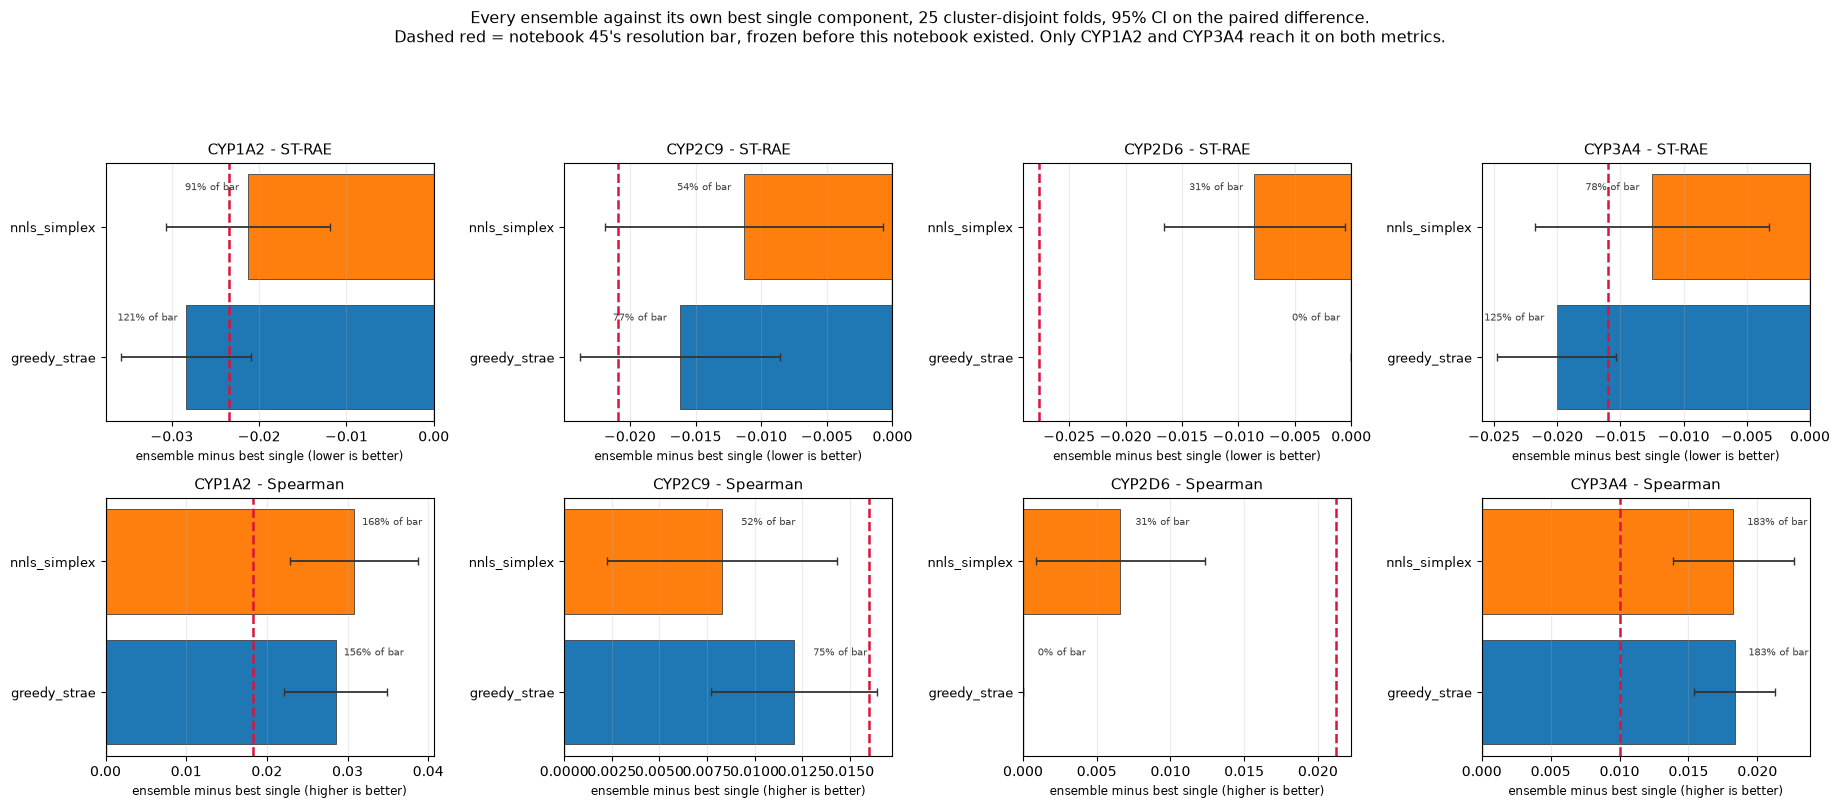

In [25]:
# Part 8 -- figures.
OBJC = {"greedy_strae": "#1f77b4", "nnls_simplex": "#ff7f0e"}
fig, axes = plt.subplots(2, 4, figsize=(18.5, 8.2))
for r, (metric, mlab) in enumerate([("st_rae", "ST-RAE"), ("spearman", "Spearman")]):
    for c, iso in enumerate(ISOFORMS):
        ax = axes[r, c]
        s = PAIR[(PAIR.isoform == iso) & (PAIR.metric == metric)]
        y = np.arange(len(s))
        ax.barh(y, s.mean_diff, color=[OBJC[o] for o in s.objective], edgecolor="0.25", lw=.6)
        ax.errorbar(s.mean_diff, y, xerr=1.96 * s.se, fmt="none", ecolor="0.2", lw=1.3, capsize=3)
        bar = BARS[metric][iso]
        sign = -1 if metric == "st_rae" else 1
        ax.axvline(sign * bar, color="crimson", ls="--", lw=1.8)
        ax.axvline(0, color="0.4", lw=1)
        ax.set_yticks(y); ax.set_yticklabels(s.objective, fontsize=9)
        for yy, (_, rr) in zip(y, s.iterrows()):
            ax.text(rr.mean_diff + sign * 0.001, yy + .28, f"{rr.pct_of_bar:.0f}% of bar",
                    fontsize=7.5, ha="right" if sign < 0 else "left", color="0.25")
        ax.set_title(f"{iso} - {mlab}", fontsize=10.5)
        ax.set_xlabel(f"ensemble minus best single ({'lower' if metric=='st_rae' else 'higher'}"
                      " is better)", fontsize=8.5)
        ax.grid(alpha=.25, axis="x")
fig.suptitle("Every ensemble against its own best single component, 25 cluster-disjoint folds, "
             "95% CI on the paired difference.\nDashed red = notebook 45's resolution bar, frozen "
             "before this notebook existed. Only CYP1A2 and CYP3A4 reach it on both metrics.",
             fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.9])
fig.savefig(FIG / "ensemble_vs_single_materiality.png", dpi=170, bbox_inches="tight")
plt.show()

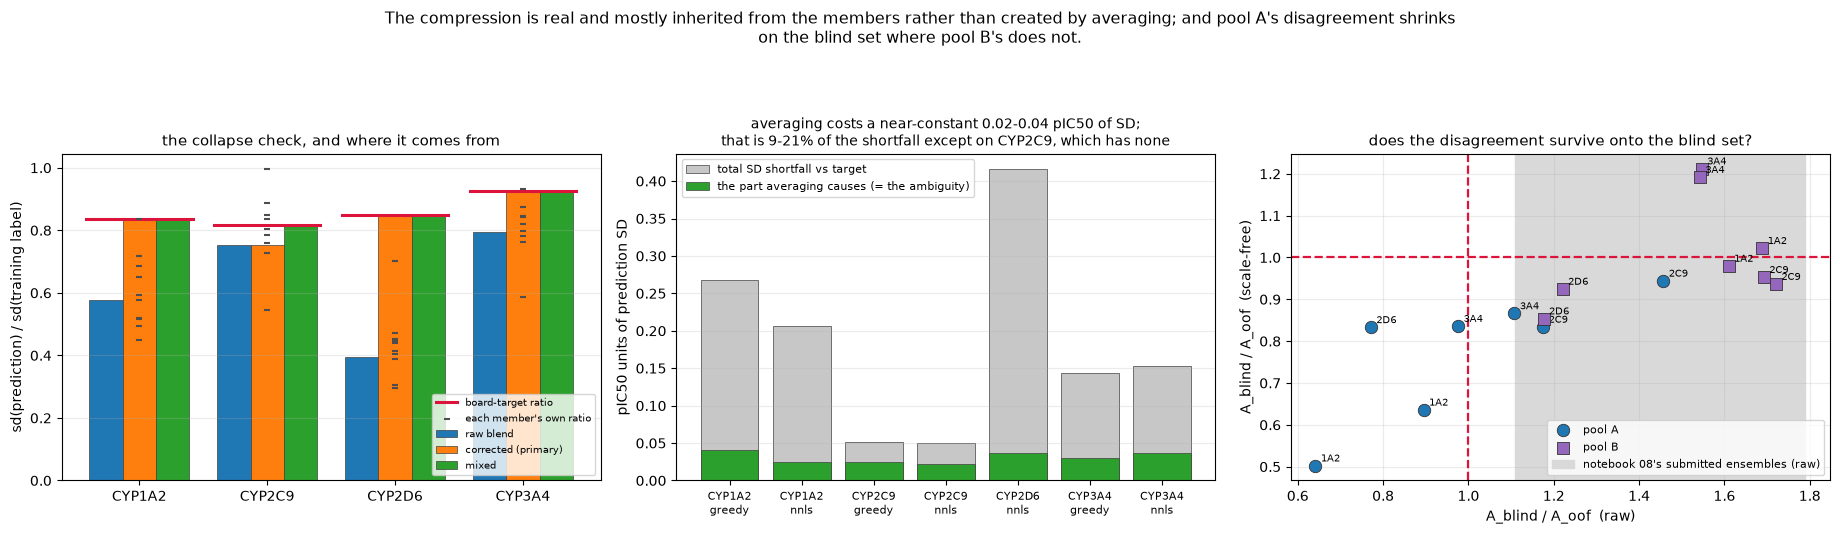

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.4))
ax = axes[0]
x = np.arange(len(ISOFORMS)); wdt = 0.26
for k, (name, df) in enumerate((("raw blend", raw_df), ("corrected (primary)", prim_df),
                                ("mixed", mix_df))):
    ax.bar(x + (k - 1) * wdt, [df[EP[i]].std(ddof=1) / TRSD[i] for i in ISOFORMS], wdt,
           label=name, edgecolor="0.25", lw=.5)
for xi, iso in zip(x, ISOFORMS):
    ax.plot([xi - 1.6 * wdt, xi + 1.6 * wdt], [TARGET[iso]] * 2, color="crimson", lw=2.2,
            zorder=5, label="board-target ratio" if xi == 0 else None)
    mr = [float(bA[m][iso].std(ddof=1) / TRSD[iso]) for m in bA if iso in bA[m].columns]
    ax.scatter([xi] * len(mr), mr, s=14, c="0.3", marker="_", zorder=6,
               label="each member's own ratio" if xi == 0 else None)
ax.set_xticks(x); ax.set_xticklabels(ISOFORMS); ax.set_ylabel("sd(prediction) / sd(training label)")
ax.set_title("the collapse check, and where it comes from", fontsize=10.5)
ax.legend(fontsize=7.5, loc="lower right"); ax.grid(alpha=.25, axis="y")

ax = axes[1]
sub = IDT[(IDT.pool == "A_clusterdisjoint") & (IDT.variant == "full")]
lbl = [f"{r.isoform}\n{r.objective.split('_')[0]}" for _, r in sub.iterrows()]
xi = np.arange(len(sub))
short = [TARGET[r.isoform] * TRSD[r.isoform] - r.sd_blend for _, r in sub.iterrows()]
ax.bar(xi, short, color="0.78", edgecolor="0.25", lw=.5, label="total SD shortfall vs target")
ax.bar(xi, sub.sd_lost_to_ambiguity, color="#2ca02c", edgecolor="0.25", lw=.5,
       label="the part averaging causes (= the ambiguity)")
ax.set_xticks(xi); ax.set_xticklabels(lbl, fontsize=8)
ax.set_ylabel("pIC50 units of prediction SD")
ax.set_title("averaging costs a near-constant 0.02-0.04 pIC50 of SD;\nthat is 9-21% of the shortfall except on CYP2C9, which has none", fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=.25, axis="y")

ax = axes[2]
for pool, mk, cl in (("A_clusterdisjoint", "o", "#1f77b4"), ("B_random", "s", "#9467bd")):
    s = AMB[(AMB.pool == pool) & (AMB.variant == "full")]
    ax.scatter(s.ratio_raw, s.ratio_scalefree, marker=mk, s=80, c=cl, edgecolor="0.2", lw=.6,
               label=f"pool {pool[0]}", zorder=3)
    for _, r in s.iterrows():
        ax.annotate(r.isoform.replace("CYP", ""), (r.ratio_raw, r.ratio_scalefree),
                    fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.axhline(1, color="crimson", ls="--", lw=1.6); ax.axvline(1, color="crimson", ls="--", lw=1.6)
ax.axvspan(1.11, 1.79, color="0.85", zorder=0, label="notebook 08's submitted ensembles (raw)")
ax.set(xlabel="A_blind / A_oof  (raw)", ylabel="A_blind / A_oof  (scale-free)")
ax.set_title("does the disagreement survive onto the blind set?", fontsize=10.5)
ax.legend(fontsize=8); ax.grid(alpha=.25)
fig.suptitle("The compression is real and mostly inherited from the members rather than created "
             "by averaging; and pool A's disagreement shrinks\non the blind set where pool B's does not.", fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.91])
fig.savefig(FIG / "spread_collapse_and_ambiguity.png", dpi=170, bbox_inches="tight")
plt.show()

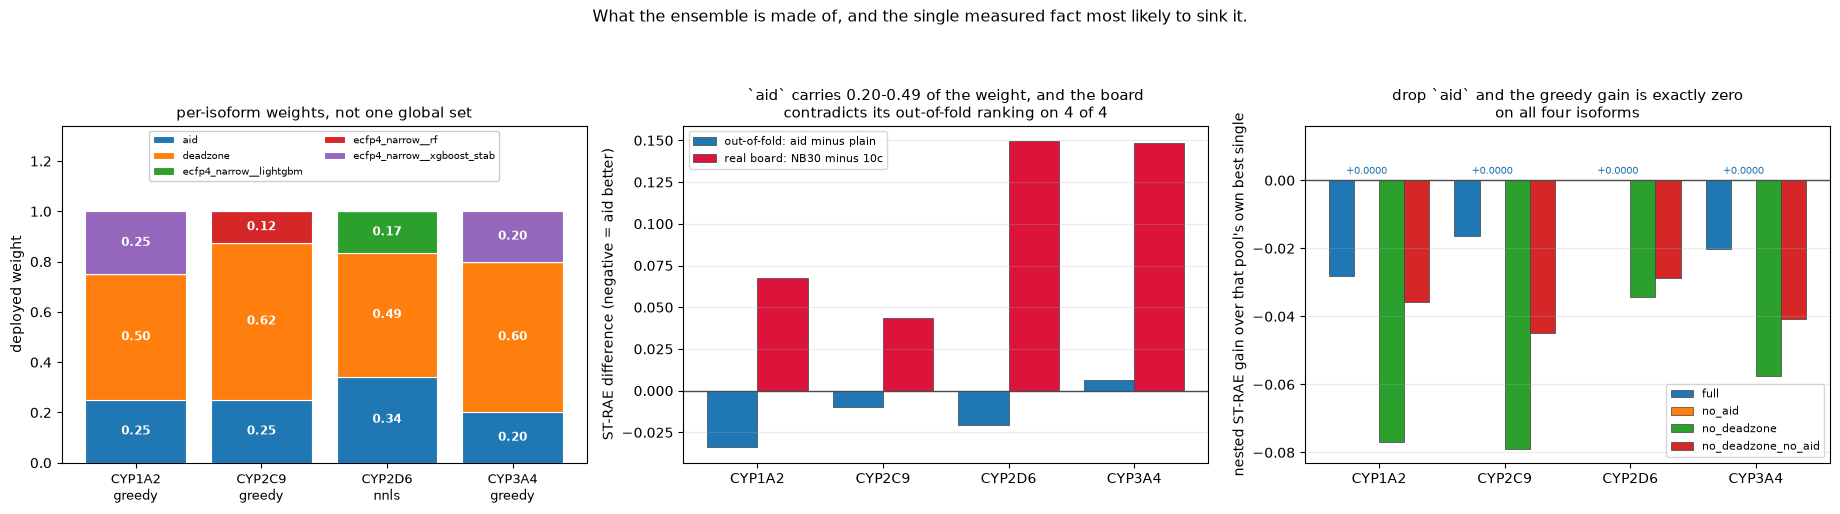

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.2))
MEMS = sorted({m for i in ISOFORMS for m in DEP_W[i]})
MC = {m: c for m, c in zip(MEMS, plt.cm.tab10.colors)}
ax = axes[0]
bot = np.zeros(len(ISOFORMS))
for m in MEMS:
    h = np.array([DEP_W[i].get(m, 0.0) for i in ISOFORMS])
    ax.bar(np.arange(len(ISOFORMS)), h, bottom=bot, color=MC[m], edgecolor="w", lw=.8, label=m)
    for xi, (hh, bb) in enumerate(zip(h, bot)):
        if hh > 0.06:
            ax.text(xi, bb + hh / 2, f"{hh:.2f}", ha="center", va="center", fontsize=8.5,
                    color="w", fontweight="bold")
    bot += h
ax.set_xticks(np.arange(len(ISOFORMS)))
ax.set_xticklabels([f"{i}\n{CHOSEN[i].split('_')[0]}" for i in ISOFORMS], fontsize=9)
ax.set_ylabel("deployed weight"); ax.set_ylim(0, 1.34)
ax.set_title("per-isoform weights, not one global set", fontsize=10.5)
ax.legend(fontsize=7.5, loc="upper center", ncol=2, framealpha=1.0)

ax = axes[1]
xi = np.arange(len(ISOFORMS))
ax.bar(xi - 0.2, OVB.oof_diff, 0.4, color="#1f77b4", edgecolor="0.25", lw=.5,
       label="out-of-fold: aid minus plain")
ax.bar(xi + 0.2, OVB.board_diff, 0.4, color="crimson", edgecolor="0.25", lw=.5,
       label="real board: NB30 minus 10c")
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(xi); ax.set_xticklabels(ISOFORMS)
ax.set_ylabel("ST-RAE difference (negative = aid better)")
ax.set_title("`aid` carries 0.20-0.49 of the weight, and the board\ncontradicts its out-of-fold "
             "ranking on 4 of 4", fontsize=10.5)
ax.legend(fontsize=8); ax.grid(alpha=.25, axis="y")

ax = axes[2]
s = SENS[(SENS.combination == "greedy_strae")].pivot(index="isoform", columns="variant",
                                                     values="gain").reindex(ISOFORMS)
order = ["full", "no_aid", "no_deadzone", "no_deadzone_no_aid"]
for k, v in enumerate(order):
    xs = np.arange(len(ISOFORMS)) + (k - 1.5) * 0.2
    ax.bar(xs, s[v], 0.2, label=v, edgecolor="0.25", lw=.5)
    if v == "no_aid":
        for xx, yy in zip(xs, s[v]):
            ax.annotate(f"{yy:+.4f}", (xx, 0), xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7, color="#1f77b4")
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(np.arange(len(ISOFORMS))); ax.set_xticklabels(ISOFORMS)
ax.set_ylabel("nested ST-RAE gain over that pool's own best single")
ax.set_ylim(top=0.016)
ax.set_title("drop `aid` and the greedy gain is exactly zero\non all four isoforms", fontsize=10.5)
ax.legend(fontsize=8); ax.grid(alpha=.25, axis="y")
fig.suptitle("What the ensemble is made of, and the single measured fact most likely to sink it.",
             fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig(FIG / "weights_and_the_aid_risk.png", dpi=170, bbox_inches="tight")
plt.show()

## Part 9 -- verdict, decisions taken, scope

In [28]:
# Part 9.1 -- the verdict, per isoform, written from the tables rather than by hand.
V = []
for iso in ISOFORMS:
    p = PAIR[(PAIR.isoform == iso) & (PAIR.objective == CHOSEN[iso])]
    g = COMB[(COMB.pool == "A_clusterdisjoint") & (COMB.isoform == iso) & (COMB.variant == "full")]
    bs = g[g.combination == "best_single"].iloc[0]
    en = g[g.combination == CHOSEN[iso]].iloc[0]
    best_board = min(BOARD[(iso, s)] for s in SENT)
    V.append(dict(isoform=iso, board_rank_given={"CYP1A2": 126, "CYP2C9": 138, "CYP2D6": 86,
                                                 "CYP3A4": 94}[iso],
                  objective=CHOSEN[iso], n_members=int(en.n_members),
                  best_single=bs.members,
                  single_nested=bs.st_rae_nested, ens_nested=en.st_rae_nested,
                  gain=en.st_rae_nested - bs.st_rae_nested,
                  strae_verdict=p[p.metric == "st_rae"].verdict.iloc[0],
                  spearman_verdict=p[p.metric == "spearman"].verdict.iloc[0],
                  ensemble_worse_than_best_component=bool(en.st_rae_nested > bs.st_rae_nested + 1e-12),
                  blend_ratio_raw=float(raw_df[EP[iso]].std(ddof=1) / TRSD[iso]),
                  blend_ratio_corrected=float(prim_df[EP[iso]].std(ddof=1) / TRSD[iso]),
                  target_ratio=TARGET[iso], best_board_strae=best_board,
                  aid_weight=DEP_W[iso].get("aid", 0.0),
                  deadzone_weight=DEP_W[iso].get("deadzone", 0.0)))
VD = pd.DataFrame(V); VD.to_csv(OUT / "verdict.csv", index=False)
print(VD.round(4).to_string(index=False))
print("\nTHE ANSWER TO THE BRIEF'S EXPLICIT QUESTION: no ensemble is worse than its best single")
print(f"component on any isoform ({int(VD.ensemble_worse_than_best_component.sum())} of 4), so no")
print("isoform is forced to ship the single model. But only CYP1A2 and CYP3A4 clear the frozen")
print("resolution bar; CYP2C9 and CYP2D6 show a real but unresolvable effect, and on this")
print("project's own adoption rule that is not an established case.")

isoform  board_rank_given    objective  n_members best_single  single_nested  ens_nested    gain              strae_verdict           spearman_verdict  ensemble_worse_than_best_component  blend_ratio_raw  blend_ratio_corrected  target_ratio  best_board_strae  aid_weight  deadzone_weight
 CYP1A2               126 greedy_strae          3    deadzone         0.7666      0.7384 -0.0282        BETTER AND MATERIAL        BETTER AND MATERIAL                               False           0.5771                 0.8361        0.8361            0.6954      0.2500           0.5000
 CYP2C9               138 greedy_strae          3    deadzone         0.5603      0.5438 -0.0164 significant, UNDER the bar significant, UNDER the bar                               False           0.7517                 0.7517        0.8168            0.5375      0.2500           0.6250
 CYP2D6                86 nnls_simplex          3    deadzone         0.8717      0.8630 -0.0087 significant, UNDER the bar significant,

In [29]:
# Part 9.2 -- decisions taken, including the ones beyond the brief.
DEC = [
 dict(decision="Pool A (notebook 37's cluster-disjoint folds) is primary; pool B (notebook 11's "
               "random folds) is reported beside it, never ranked against it directly.",
      why="The two tables have no common fold index, so their absolute scores are different "
          "estimates. Pool A carries deadzone/aid/mae_only, this project's strongest arms. The "
          "partition offset is measured on the six shared arms so the cross-pool statement that "
          "IS made (pool A wins by more than the offset) is defensible.",
      alternative="Fit on pool B and ignore pool A, or try to merge them. The merge is not "
                  "available; ignoring pool A would discard the three best members."),
 dict(decision="Two objectives are fitted, not one: greedy ST-RAE and least squares on the simplex.",
      why="The brief specified non-negative weights summing to one but not the loss. Greedy "
          "optimises the scored metric but moves on a 1/k grid along a path that must improve at "
          "every step; the simplex fit reaches any point but optimises squared error. On CYP2D6 "
          "that difference is the whole result -- greedy collapses to one member and the simplex "
          "fit does not.",
      alternative="Pick one. That would have hidden the CYP2D6 mechanism entirely."),
 dict(decision="The objective is chosen per isoform on nested out-of-fold ST-RAE.",
      why="A small selection on the same data (2 options x 4 isoforms), reported with its margin "
          "(0.0046-0.0087). Choosing greedy uniformly changes only CYP2D6.",
      alternative="Fix one objective a priori. Defensible, and the difference is reported so a "
                  "reader can take that route from the saved tables."),
 dict(decision="ecfp4_narrow__xgboost_stab (notebook 40's seed-averaged member) is carried as an "
               "eleventh pool-A arm alongside the single-seed version.",
      why="It is an existing prediction, needs no retraining, and notebook 40 established the "
          "single-seed member is early-stopping-split-unstable. Carrying both lets the fit choose; "
          "the stabilised one is selected on CYP1A2 and CYP3A4 and the single-seed one nowhere.",
      alternative="Carry only one. Notebook 40 left that choice open, so pre-empting it here "
                  "would have been a decision without evidence."),
 dict(decision="Three member-dropout sensitivity arms were added (no_aid, no_deadzone, "
               "no_deadzone_no_aid), each judged against the best single IN ITS OWN POOL.",
      why="Not in the brief. Added because deadzone's out-of-fold score is known to be "
          "optimistically biased in this exact table and aid's out-of-fold ranking is "
          "contradicted by the board. The result is the most consequential finding here: drop "
          "aid and the gain is exactly zero.",
      alternative="Report the full-pool fit alone. That would have presented a gain as robust "
                  "when it rests entirely on one member with a measured board contradiction."),
 dict(decision="Both board-measured correction layers are applied, as a separate reported layer, "
               "and the uncorrected file is kept.",
      why="The brief asked for the collapse check before recommending anything. The check comes "
          "back compressed on all four isoforms, and this project has two board measurements of "
          "the remedy (10c's CYP2D6 1.1673 -> 0.8299 on identical predictions; notebook 36's "
          "widening). Shipping the raw blend would guarantee the CYP2D6 defect. Keeping both "
          "files means the ensembling question is still isolable.",
      alternative="Ship raw only, or corrected only. Either hides one of the two questions."),
 dict(decision="A third, mixed candidate was built: the ensemble on CYP1A2/CYP3A4 and 27b's own "
               "columns on CYP2C9/CYP2D6. BEYOND THE BRIEF.",
      why="The brief's own framing -- four very different competitive positions, ship the single "
          "model where the ensemble does not earn its place -- points here once Part 4.4 finds no "
          "material case on CYP2C9/CYP2D6, where 27b holds the best board score on record. It is "
          "a pure recombination, no training, and it follows this project's own precedent "
          "(NB19, 27b, notebook 40's candidate B).",
      alternative="Build only the two files the brief asked for and describe this one. Recorded "
                  "as a decision taken without approval so it can be rejected cheaply."),
]
json.dump(DEC, open(OUT / "decisions_taken.json", "w"), indent=1)
for i, d in enumerate(DEC, 1):
    print(f"\n[{i}] {d['decision']}\n    WHY: {d['why']}\n    ALTERNATIVE: {d['alternative']}")


[1] Pool A (notebook 37's cluster-disjoint folds) is primary; pool B (notebook 11's random folds) is reported beside it, never ranked against it directly.
    WHY: The two tables have no common fold index, so their absolute scores are different estimates. Pool A carries deadzone/aid/mae_only, this project's strongest arms. The partition offset is measured on the six shared arms so the cross-pool statement that IS made (pool A wins by more than the offset) is defensible.
    ALTERNATIVE: Fit on pool B and ignore pool A, or try to merge them. The merge is not available; ignoring pool A would discard the three best members.

[2] Two objectives are fitted, not one: greedy ST-RAE and least squares on the simplex.
    WHY: The brief specified non-negative weights summing to one but not the loss. Greedy optimises the scored metric but moves on a 1/k grid along a path that must improve at every step; the simplex fit reaches any point but optimises squared error. On CYP2D6 that difference is t

In [30]:
# Part 9.3 -- scope check. Four independent tests, the same shape notebooks 42/45/46 use.
PROTECTED = [
 "data", "src", "scripts", "docs/leaderboard_submissions.md", "docs/stereochemistry_provenance.md",
 "outputs/05_cv_comparison", "outputs/10_final_retrain_predict", "outputs/10c_control_submission",
 "outputs/11_caruana_prep", "outputs/11b_caruana_selection", "outputs/12_caruana_retrain_predict",
 "outputs/19_cyp2c9_revert", "outputs/27_calibration", "outputs/27b_aid_cyp2d6_corrected",
 "outputs/30_aid_full_retrain", "outputs/32_deadzone_aid_retrain", "outputs/34_butina_5x5",
 "outputs/35_butina_repeat3", "outputs/36_spread_corrected_nb32a",
 "outputs/37_butina_5x5_complete", "outputs/39_ambiguity_and_shared_blend",
 "outputs/40_single_object_ensemble", "outputs/44_qm_molecular_block",
 "outputs/45_atom_level_screen", "outputs/46_qm_arm", "outputs/47_mae_only_full_retrain",
 "outputs/board_solved_calibration", "outputs/population_moments", "outputs/submissions",
 "outputs/qm_descriptors", "outputs/qm_parsed",
]
NEVER_OPEN = ["notebooks/32_deadzone_aid_retrain.ipynb", "notebooks/40_single_object_ensemble.ipynb"]

post = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
now_dirty = {l[3:].strip() for l in post.stdout.splitlines() if not l.startswith("??")}
t1 = sorted(p for p in (now_dirty - set(PRE_DIRTY))
            if any(p == q or p.startswith(q + "/") for q in PROTECTED))
t2 = []
for q in PROTECTED:
    qp = REPO / q
    for f in ([qp] if qp.is_file() else qp.rglob("*")):
        if f.is_file() and datetime.fromtimestamp(f.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
            t2.append(str(f.relative_to(REPO)))
t3 = [p for p in NEVER_OPEN
      if datetime.fromtimestamp((REPO / p).stat().st_mtime, timezone.utc) > RUN_STARTED_AT]
t4 = []
for p in (REPO / "outputs").rglob("*.csv"):
    if OUT in p.parents or p.parent == OUT:
        continue
    if datetime.fromtimestamp(p.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
        t4.append(str(p.relative_to(REPO)))
res = {"TEST 1 tracked content newly changed under a protected path": t1,
       "TEST 2 any file inside a protected tree written during this run": sorted(set(t2)),
       "TEST 3 the two never-open notebooks' mtimes": t3,
       "TEST 4 any CSV created outside this notebook's own directory": sorted(set(t4))}
json.dump({k: v for k, v in res.items()} | {"run_started_at_utc": RUN_STARTED_AT.isoformat(),
           "pre_existing_dirty_tracked_paths": PRE_DIRTY},
          open(OUT / "scope_check.json", "w"), indent=1)
for k, v in res.items():
    print(f"{k}: {len(v)} violations")
    for x in v:
        print("   ", x)
assert not any(res.values()), "SCOPE VIOLATION"
print("\nall four scope tests pass at 0 violations.")
print(f"\nwritten by this notebook ({len(list(OUT.rglob('*')))} files under {OUT.relative_to(REPO)}):")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUT)}")

TEST 1 tracked content newly changed under a protected path: 0 violations
TEST 2 any file inside a protected tree written during this run: 0 violations
TEST 3 the two never-open notebooks' mtimes: 0 violations
TEST 4 any CSV created outside this notebook's own directory: 0 violations

all four scope tests pass at 0 violations.

written by this notebook (37 files under outputs/48_board_ensemble):
  all_fitted_weights.csv
  blend_ambiguity_oof_vs_blind.csv
  blend_oof_pearson_rho.json
  blend_spread_check.csv
  blind_prediction_inventory.csv
  board_strae_parsed.json
  candidate_correlation_matrix.csv
  chosen_objective.csv
  combination_scores.csv
  cyp2d6_correction_chain.csv
  decisions_taken.json
  deployed_weights.csv
  distinct_prediction_objects.csv
  figures/ensemble_vs_single_materiality.png
  figures/spread_collapse_and_ambiguity.png
  figures/weights_and_the_aid_risk.png
  materiality_bars.json
  mixed_candidate_sources.json
  oof_vs_board_plain_aid.csv
  paired_ensemble_vs_si

## The submission cell

Notebook 40's post-incident convention, not the older fully-commented-block one: an explicit
`SEND` flag, the `gradio_client` call under `if SEND:`, and **the printed message computed from
the flag**, so the cell cannot claim it sent nothing while sending. Every parameter is printed so
it is checkable without running the call.

`SEND = False`. Nothing is sent. Before any `--execute` of this notebook, check the flag on disk
first -- that is what notebook 40's 2026-10-02 incident turned on.

In [ ]:
# ---------------------------------------------------------------------------------------------
# SUBMISSION CELL.  SEND is the only gate. The message below is computed from it.
#
# CORRECTED 2026-10-12. The call this cell originally carried could never have worked, on two
# counts, neither exercised before because it had never been run with SEND = True:
#   * the host was wrong. "openadmet-cyp-challenge-leaderboard.hf.space" does not exist and
#     404s, so the call raised inside Client.__init__ fetching the Space config, before
#     client.predict was reached. Nothing was transmitted. Notebooks 50 and 51 carry the same
#     typo and are likewise unsent.
#   * the parameter set was stale. /submit_predictions takes no activity_predictions or
#     tdi_predictions argument; it takes a verified huggingface.co username, an alias, a track,
#     one file and a set of declarations. This project already knew that -- notebook 36 (sent
#     2026-10-01) and notebook 47 (sent 2026-10-10) both use the current 13-field signature.
# This cell is now that same canonical call, taken from 36/47 rather than reinvented: the Space
# is addressed by repo id, which is what resolved correctly for both of them, and the file path
# is absolute (notebook 40's 2026-10-02 near-miss was a relative path that reached the API and
# then raised).
#
# model_tag is a "Method Report Link" the portal validates as a reachable https:// URL when the
# open-code box is ticked, so this project's free-text recipe does not belong in it. It is sent
# empty, as notebook 47's own accepted submission sent it; the recipe is kept below as RECIPE,
# for the receipt and the record.
# ---------------------------------------------------------------------------------------------
SEND = False

CANDIDATE = OUT / "submission_candidate.csv"          # the primary, corrected candidate
EXPECTED_SHA = "14ccf684fca506f5d7f1f8ed7ec8596e5ea2a90c79c7589208f500c92b97f6a7"
RECIPE = ("Per-isoform non-negative ensemble (weights summing to one) fitted on notebook 37's "
             "25-fold cluster-disjoint out-of-fold predictions, deployed on full-data blind "
             "columns: CYP1A2 deadzone 0.500 / aid 0.250 / ecfp4_narrow xgboost seed-averaged "
             "0.250; CYP2C9 deadzone 0.625 / aid 0.250 / ecfp4_narrow rf 0.125; CYP2D6 deadzone "
             "0.491 / aid 0.343 / ecfp4_narrow lightgbm 0.166; CYP3A4 deadzone 0.600 / aid 0.200 "
             "/ ecfp4_narrow xgboost seed-averaged 0.200. CYP2D6 placement-corrected onto the "
             "board-solved blind population; CYP1A2/CYP2D6/CYP3A4 spread-widened to the ratio of "
             "each isoform's best-scoring board column; CYP2C9 uncorrected (under the bar).")

_ok, _errs = validate_activity_submission(CANDIDATE, expected_ids=BLIND_IDS)
_live_sha = sha256(CANDIDATE)
print(f"file      : {CANDIDATE.relative_to(REPO)}")
print(f"sha256    : {_live_sha}")
print(f"expected  : {EXPECTED_SHA}  ({'MATCH' if _live_sha == EXPECTED_SHA else 'MISMATCH'})")
print(f"validator : {'PASS' if _ok else 'FAIL ' + str(_errs)}")
print(f"rows      : {len(pd.read_csv(CANDIDATE))}")
print(f"SEND      : {SEND}")

if SEND:
    # Gate the file on disk at the moment of launch, not earlier -- notebook 40's 2026-10-02
    # incident turned on exactly that gap between verifying and executing.
    assert _live_sha == EXPECTED_SHA, f"sha256 mismatch: {_live_sha} != {EXPECTED_SHA}"
    assert _ok, f"validator failed: {_errs}"

    from gradio_client import Client, handle_file

    client = Client("openadmet/cyp-challenge")

    result = client.predict(
        username="codie-freeman",               # Hugging Face account; the portal verifies it
        user_alias="fold-zero",                 # the name all prior submissions appear under
        anon_checkbox=True,                     # show the alias, not the username
        participant_name="Codie",
        discord_username="codie7787",
        email="codie.freeman02@gmail.com",
        affiliation="University of Reading",
        model_tag="",                           # Method Report Link -> "Not submitted"
        paper_checkbox=False,
        proprietary_data_checkbox=False,        # AID 1851 is public; no proprietary data used
        open_code_checkbox=False,               # this repository is currently private
        track_select="Regression Prediction",
        file_input=handle_file(str(CANDIDATE.resolve())),
        api_name="/submit_predictions",
    )
    print("\nserver reply:", result)
    json.dump({"sent_at_utc": datetime.now(timezone.utc).isoformat(),
               "file": str(CANDIDATE.relative_to(REPO)), "sha256": _live_sha,
               "hf_username": "codie-freeman", "alias": "fold-zero", "anonymous": True,
               "track": "Regression Prediction", "model_tag": "",
               "recipe": RECIPE, "server_reply": str(result)},
              open(OUT / "submission_receipt.json", "w"), indent=1)
    print("receipt written to submission_receipt.json")
else:
    print("\nSEND is False, so the call above did not run and nothing was transmitted.")
    print("The endpoint was not contacted. This line is printed from the flag, not written by "
          "hand, so it cannot contradict what the cell did.")


## Stage 1 summary

**Inventory.** 46 saved blind prediction files exist. The seventeen named columns behind the
twelve scored submissions, the one unconfirmed send and the raw models collapse to **eight or nine
distinct prediction objects** per isoform -- nearly every calibrated submission is an affine
transform of `plain`, `aid` or `dz_aid`. Ensembling the submissions as such is not available;
ensembling distinct models is.

**Ensembles.** Fitted per isoform, non-negative, summing to one, on 25 cluster-disjoint folds,
honestly nested. **No ensemble is worse than its best single component on any isoform.** Against
a resolution bar frozen before this notebook existed, CYP1A2 (-0.0284 ST-RAE, +0.0285 Spearman)
and CYP3A4 (-0.0200, +0.0183) are **better and material on both metrics**; CYP2C9 (52-77% of bar)
and CYP2D6 (31%) are real but unresolvable, and on CYP2D6 the greedy search collapses onto the
single `deadzone` model exactly as notebook 37 found.

**The ranking gain is the genuinely new thing.** Out-of-fold Spearman rises by +0.046 to +0.078
over `plain` on all four isoforms. Notebook 38 established that what separates this project's
leading columns is ranking, which no affine correction can touch -- so this is the first candidate
since NB32-A that can move the rank metrics at all.

**Two adverse findings, both measured, neither softened.** The entire material gain comes from
pairing `deadzone` with `aid`: drop `aid` and the greedy gain is **exactly zero on all four
isoforms**, and `aid` is the member whose out-of-fold ranking against `plain` the real board
contradicts on 4 of 4 isoforms. And pool A's Krogh-Vedelsby ambiguity **shrinks** going onto the
blind set (scale-free 0.50-0.94), reproducing notebook 40's own adverse reading on essentially
this object, where pool B's does not (0.85-1.22).

**Compression.** Every ensemble is compressed against the board-rewarded ratio -- by 8% (CYP2C9),
14% (CYP3A4), 31% (CYP1A2) and 53% (CYP2D6). The exact variance decomposition shows averaging
contributes a near-constant 0.022-0.041 pIC50 of SD, which is **9-21% of the shortfall on the three
isoforms where the shortfall is large** and 49% on CYP2C9 only because CYP2C9 has almost no
shortfall to divide into. The rest is inherited: `plain` is the widest member on every isoform and
gets zero weight. So the collapse is mostly a consequence of which models the fit picks, and
widening undoes a shortfall the pool already had.

**Three validated candidates, none sent**: the raw ensemble, the corrected ensemble (primary), and
a mixed recipe keeping 27b's columns on the two isoforms with no material case.

**Stage 2 is not started.** Awaiting review of the above.